# <font color = "red">**Day 26: Build the Digital Twin of a Microscope**</font>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kbarakati/athena_camm_hackathon/blob/k4my4r/docs/day_26_20112026/Day_26_Digital_Twin_Challenge.ipynb)

**Challenge overview**

You are given access to a **scanning transmission electron microscope** (simulated) that looks at a **real**
plasmonic nanoparticle specimen, with a real EELS spectrum at every pixel (the Day-17 data). Like every real
instrument it has its own hidden behaviour: the sample **drifts** (a slow trend, an oscillation and jitter), **fast
scans are blurry** and noisy, and **registration** fails on featureless areas. Every instrument is different, and the
datasheet only gives typical numbers.

**<font color = "blue">Your task is to build a digital twin of the instrument (a model that predicts where the
beam will really be and how sharp a scan will be) and to show that it guides measurements and calibration better
than the datasheet.</font>**

### <font color = "purple">**What we give you and what you build**</font>

| we give you (the instrument) | you build (the twin) |
|---|---|
| `Scan(row, col, scan_time)`: costs 3 × scan_time; faster is blurrier | **Challenge 1:** a characterisation routine and a blur law `blur_sigma(scan_time)` |
| `Calibrate()`: costs 1; registers the latest scan and corrects the drift | **Challenge 2:** a drift forecast `predict_offset(t)` → mean and covariance |
| `Spectrum(row, col)`: costs 1; the spectrum where the beam **really** is | **Challenge 3 (optional):** your own agent that uses the twin |
| a reference specimen with a **known** image, to characterise the instrument | |
| 10 practice instruments (their truth can be revealed to check yourself) | |

### <font color = "purple">**The challenges**</font>

| | task | how it is checked |
|---|---|---|
| **Challenge 1** | **Characterise your instrument.** Within 300 time units on the reference specimen, measure the blur law and the drift statistics | your blur law against the truth (practice instruments) |
| **Challenge 2** | **Forecast the beam.** In a campaign, predict where the beam will really be, with honest uncertainty | offset error and coverage of your 95 % band, against the datasheet |
| **Challenge 3** | **Guide the experiment.** A fixed controller uses your twin to choose scan speed, compensate drift and decide when to calibrate while it collects spectra to learn structure → property (1.0–1.3 eV band). Optionally, write your own agent | gain in prediction RMSE and in image–spectrum pairing, versus the datasheet and relative to a perfect twin |

**Final score:** TWIN SCORE = 0.5 × accuracy (Challenges 1 + 2) + 0.5 × value (Challenge 3). Your own agent is a
separate award. The final ranking uses **secret instruments**, so tune on the practice ones as much as you like.

### <font color = "purple">**Instructions**</font>

1. *Runtime → Run all* once (about 2 minutes; the first cell downloads the Day-17 data file).
2. Read sections 1–2 to meet the instrument. You do not need to read the hidden simulator cells.
3. Edit only the three cells that start with `# >>> CHALLENGE`. Each is followed by a check cell.
4. Run section **Your score** and answer the questions.
5. **Submit** as on previous days: save this notebook with all outputs as `<YourName>_Day_26_Digital_Twin_Challenge.ipynb`
   and add it to `docs/day_26_DDMMYYYY/` in the hackathon repository by pull request.

<font color = "red">**Rules**</font>
- Your twin may use only what the sessions give it: observations, the reference image, and `locate()` / `render()`.
- Do not use the simulator's internals (`._ins`, `._profile`, `make_profile`, `make_drift`, `reveal_truth`) or the
  data file in the CHALLENGE cells. `reveal_truth` is for the check cells only, and only works on practice instruments.
- Each campaign starts from a fresh copy of your characterised twin.

## <font color = "purple">**0.**</font> Setup

In [1]:
import json, copy, time
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#@title Load the data and build the specimens (run, do not edit)
import os, json, subprocess
import numpy as np

DATA_FILE = os.environ.get("EELS_DATA", "/content/Plasmonic_sets_hackathon.npy" if os.path.isdir("/content")
                           else "Plasmonic_sets_hackathon.npy")
if not os.path.exists(DATA_FILE):          # the Day-17 file: 584 MB, about a minute on Colab
    subprocess.run(["gdown", "--fuzzy", "1FKmlRTRDImQS91V4YQjcQHoJU19X6P_6", "-O", DATA_FILE], check=True)
_raw = np.load(DATA_FILE, allow_pickle=True).tolist()

BIN, BAND, BLOCK, GUARD = 8, (1.0, 1.3), (11, 7), 2
TEST_BLOCKS = [(0, 0), (2, 2), (1, 4), (0, 6), (2, 8)]
VAL_BLOCKS = [(2, 1), (0, 3), (2, 5)]


def _bin(S, e, b=BIN):
    n = len(e) // b
    return S[..., :n * b].reshape(S.shape[:-1] + (n, b)).mean(-1).astype(np.float32), e[:n * b].reshape(n, b).mean(1)


def band_area(spectrum, energy, band):
    m = (energy >= band[0]) & (energy <= band[1])
    return np.trapezoid(np.asarray(spectrum)[..., m], energy[m], axis=-1)


def _blocks(shape, blocks):
    m = np.zeros(shape, bool)
    for i, j in blocks:
        m[i * BLOCK[0]:(i + 1) * BLOCK[0], j * BLOCK[1]:(j + 1) * BLOCK[1]] = True
    return m


def _dilate(m, r):
    out, H, W = m.copy(), m.shape[0], m.shape[1]
    for dy in range(-r, r + 1):
        for dx in range(-r, r + 1):
            sh = np.zeros_like(m)
            sh[max(-dy, 0):H + min(-dy, 0), max(-dx, 0):W + min(-dx, 0)] = m[max(dy, 0):H + min(dy, 0), max(dx, 0):W + min(dx, 0)]
            out |= sh
    return out


_d = _raw["2"]                                           # target specimen: plasmonic dataset 2
_Sb, _eb = _bin(_d["spectrum image"], _d["energy axis"])
_y = band_area(_Sb, _eb, BAND).astype(np.float32)        # the property: EELS intensity over 1.0-1.3 eV
_test, _val = _blocks(_y.shape, TEST_BLOCKS), _blocks(_y.shape, VAL_BLOCKS)
_restricted = _dilate(_test | _val, GUARD)
_spec = _Sb.copy(); _spec[_restricted] = np.nan
SPECIMEN = dict(image=_d["image"].astype(np.float32), energy=_eb.astype(np.float32), spectra=_spec, band=BAND,
                test_mask=_test, val_mask=_val, restricted_mask=_restricted,
                val_truth=np.where(_val, _y, np.nan).astype(np.float32), pixel_nm=float(_d["scale"]))
TEST_TRUTH = np.where(_test, _y, np.nan).astype(np.float32)          # used only by the organisers' grading
CALIBRATION = {k: dict(image=_raw[k]["image"].astype(np.float32), pixel_nm=float(_raw[k]["scale"])) for k in ("0", "1", "3")}
del _raw, _d, _Sb


def load_specimen():
    return SPECIMEN


def load_calibration_samples():
    return CALIBRATION


# results of the oracle twin and the datasheet twin on practice instruments 0-9 x campaigns 0-9 (for the value score)
PRACTICE_ORACLE = json.loads("{\"practice-0|0\":{\"oracle\":{\"rmse\":6.21817,\"mismatch\":0.79001},\"null\":{\"rmse\":6.02558,\"mismatch\":2.86395}},\"practice-0|1\":{\"oracle\":{\"rmse\":6.83717,\"mismatch\":0.56127},\"null\":{\"rmse\":5.90244,\"mismatch\":3.80264}},\"practice-0|2\":{\"oracle\":{\"rmse\":6.12761,\"mismatch\":0.69051},\"null\":{\"rmse\":8.54722,\"mismatch\":3.89813}},\"practice-0|3\":{\"oracle\":{\"rmse\":7.91689,\"mismatch\":0.55998},\"null\":{\"rmse\":5.70212,\"mismatch\":4.36005}},\"practice-0|4\":{\"oracle\":{\"rmse\":7.05131,\"mismatch\":0.71549},\"null\":{\"rmse\":6.14924,\"mismatch\":3.64929}},\"practice-0|5\":{\"oracle\":{\"rmse\":7.88118,\"mismatch\":1.03625},\"null\":{\"rmse\":5.50117,\"mismatch\":4.90534}},\"practice-0|6\":{\"oracle\":{\"rmse\":5.99428,\"mismatch\":0.77528},\"null\":{\"rmse\":7.38409,\"mismatch\":4.05434}},\"practice-0|7\":{\"oracle\":{\"rmse\":5.89267,\"mismatch\":0.67501},\"null\":{\"rmse\":10.86401,\"mismatch\":4.2691}},\"practice-0|8\":{\"oracle\":{\"rmse\":6.86804,\"mismatch\":0.69579},\"null\":{\"rmse\":7.39171,\"mismatch\":3.30725}},\"practice-0|9\":{\"oracle\":{\"rmse\":5.9444,\"mismatch\":1.11334},\"null\":{\"rmse\":5.67866,\"mismatch\":4.11616}},\"practice-1|0\":{\"oracle\":{\"rmse\":5.19572,\"mismatch\":1.36699},\"null\":{\"rmse\":5.4325,\"mismatch\":3.82056}},\"practice-1|1\":{\"oracle\":{\"rmse\":4.98443,\"mismatch\":0.55645},\"null\":{\"rmse\":7.81981,\"mismatch\":4.61315}},\"practice-1|2\":{\"oracle\":{\"rmse\":6.31255,\"mismatch\":1.05488},\"null\":{\"rmse\":11.09903,\"mismatch\":4.31326}},\"practice-1|3\":{\"oracle\":{\"rmse\":5.21822,\"mismatch\":1.24858},\"null\":{\"rmse\":5.34959,\"mismatch\":4.79269}},\"practice-1|4\":{\"oracle\":{\"rmse\":6.18956,\"mismatch\":0.93972},\"null\":{\"rmse\":5.50403,\"mismatch\":3.80716}},\"practice-1|5\":{\"oracle\":{\"rmse\":5.46559,\"mismatch\":1.16158},\"null\":{\"rmse\":6.2825,\"mismatch\":3.42763}},\"practice-1|6\":{\"oracle\":{\"rmse\":5.40028,\"mismatch\":0.67388},\"null\":{\"rmse\":6.23449,\"mismatch\":3.67571}},\"practice-1|7\":{\"oracle\":{\"rmse\":5.05116,\"mismatch\":0.65282},\"null\":{\"rmse\":9.82117,\"mismatch\":4.67586}},\"practice-1|8\":{\"oracle\":{\"rmse\":5.45622,\"mismatch\":1.14197},\"null\":{\"rmse\":6.87303,\"mismatch\":3.52916}},\"practice-1|9\":{\"oracle\":{\"rmse\":5.80726,\"mismatch\":0.82688},\"null\":{\"rmse\":7.40631,\"mismatch\":3.46695}},\"practice-2|0\":{\"oracle\":{\"rmse\":5.49671,\"mismatch\":0.86798},\"null\":{\"rmse\":5.75721,\"mismatch\":5.1598}},\"practice-2|1\":{\"oracle\":{\"rmse\":12.2827,\"mismatch\":3.87815},\"null\":{\"rmse\":13.31139,\"mismatch\":7.61232}},\"practice-2|2\":{\"oracle\":{\"rmse\":6.09143,\"mismatch\":1.88174},\"null\":{\"rmse\":11.14339,\"mismatch\":7.55969}},\"practice-2|3\":{\"oracle\":{\"rmse\":5.20796,\"mismatch\":1.35779},\"null\":{\"rmse\":6.51426,\"mismatch\":5.37845}},\"practice-2|4\":{\"oracle\":{\"rmse\":5.43935,\"mismatch\":1.89223},\"null\":{\"rmse\":13.79554,\"mismatch\":10.06252}},\"practice-2|5\":{\"oracle\":{\"rmse\":5.9907,\"mismatch\":1.1156},\"null\":{\"rmse\":6.71304,\"mismatch\":5.46565}},\"practice-2|6\":{\"oracle\":{\"rmse\":6.00951,\"mismatch\":2.37781},\"null\":{\"rmse\":11.16118,\"mismatch\":8.88967}},\"practice-2|7\":{\"oracle\":{\"rmse\":5.17487,\"mismatch\":1.60487},\"null\":{\"rmse\":7.87586,\"mismatch\":9.32428}},\"practice-2|8\":{\"oracle\":{\"rmse\":6.42497,\"mismatch\":1.98736},\"null\":{\"rmse\":6.71963,\"mismatch\":5.72032}},\"practice-2|9\":{\"oracle\":{\"rmse\":5.08282,\"mismatch\":2.74059},\"null\":{\"rmse\":6.49806,\"mismatch\":5.98007}},\"practice-3|0\":{\"oracle\":{\"rmse\":5.83442,\"mismatch\":0.89697},\"null\":{\"rmse\":6.65852,\"mismatch\":4.18553}},\"practice-3|1\":{\"oracle\":{\"rmse\":5.9918,\"mismatch\":1.27593},\"null\":{\"rmse\":9.76097,\"mismatch\":3.8415}},\"practice-3|2\":{\"oracle\":{\"rmse\":5.21422,\"mismatch\":0.83523},\"null\":{\"rmse\":9.11646,\"mismatch\":3.6912}},\"practice-3|3\":{\"oracle\":{\"rmse\":5.34006,\"mismatch\":0.83862},\"null\":{\"rmse\":7.57446,\"mismatch\":3.80522}},\"practice-3|4\":{\"oracle\":{\"rmse\":5.00917,\"mismatch\":0.5782},\"null\":{\"rmse\":6.21997,\"mismatch\":3.67807}},\"practice-3|5\":{\"oracle\":{\"rmse\":6.5285,\"mismatch\":1.24669},\"null\":{\"rmse\":5.22976,\"mismatch\":4.92806}},\"practice-3|6\":{\"oracle\":{\"rmse\":5.24585,\"mismatch\":1.29972},\"null\":{\"rmse\":6.40024,\"mismatch\":3.91023}},\"practice-3|7\":{\"oracle\":{\"rmse\":5.18219,\"mismatch\":0.70585},\"null\":{\"rmse\":6.37245,\"mismatch\":4.39604}},\"practice-3|8\":{\"oracle\":{\"rmse\":5.14997,\"mismatch\":0.98662},\"null\":{\"rmse\":8.20561,\"mismatch\":4.85843}},\"practice-3|9\":{\"oracle\":{\"rmse\":6.47376,\"mismatch\":0.78318},\"null\":{\"rmse\":6.43493,\"mismatch\":5.81545}},\"practice-4|0\":{\"oracle\":{\"rmse\":4.89983,\"mismatch\":0.90232},\"null\":{\"rmse\":7.72312,\"mismatch\":3.87878}},\"practice-4|1\":{\"oracle\":{\"rmse\":5.60662,\"mismatch\":0.73663},\"null\":{\"rmse\":8.76484,\"mismatch\":3.81754}},\"practice-4|2\":{\"oracle\":{\"rmse\":5.22586,\"mismatch\":1.29246},\"null\":{\"rmse\":7.48278,\"mismatch\":4.79699}},\"practice-4|3\":{\"oracle\":{\"rmse\":5.15892,\"mismatch\":2.16141},\"null\":{\"rmse\":7.94328,\"mismatch\":3.33313}},\"practice-4|4\":{\"oracle\":{\"rmse\":14.20881,\"mismatch\":1.10735},\"null\":{\"rmse\":7.0489,\"mismatch\":4.06859}},\"practice-4|5\":{\"oracle\":{\"rmse\":5.77503,\"mismatch\":0.98751},\"null\":{\"rmse\":5.59081,\"mismatch\":3.75943}},\"practice-4|6\":{\"oracle\":{\"rmse\":5.81034,\"mismatch\":1.00648},\"null\":{\"rmse\":6.9043,\"mismatch\":5.16218}},\"practice-4|7\":{\"oracle\":{\"rmse\":5.37206,\"mismatch\":1.63098},\"null\":{\"rmse\":5.88703,\"mismatch\":3.65349}},\"practice-4|8\":{\"oracle\":{\"rmse\":8.80833,\"mismatch\":1.4818},\"null\":{\"rmse\":5.87507,\"mismatch\":2.92347}},\"practice-4|9\":{\"oracle\":{\"rmse\":5.20912,\"mismatch\":0.8087},\"null\":{\"rmse\":9.18374,\"mismatch\":3.82909}},\"practice-5|0\":{\"oracle\":{\"rmse\":4.87267,\"mismatch\":1.01338},\"null\":{\"rmse\":7.06396,\"mismatch\":2.27317}},\"practice-5|1\":{\"oracle\":{\"rmse\":5.75502,\"mismatch\":0.95906},\"null\":{\"rmse\":6.01421,\"mismatch\":2.44839}},\"practice-5|2\":{\"oracle\":{\"rmse\":6.01671,\"mismatch\":0.61525},\"null\":{\"rmse\":5.95353,\"mismatch\":2.15305}},\"practice-5|3\":{\"oracle\":{\"rmse\":5.36165,\"mismatch\":1.02928},\"null\":{\"rmse\":7.19142,\"mismatch\":1.90633}},\"practice-5|4\":{\"oracle\":{\"rmse\":5.19118,\"mismatch\":0.93881},\"null\":{\"rmse\":6.90886,\"mismatch\":2.22703}},\"practice-5|5\":{\"oracle\":{\"rmse\":4.94564,\"mismatch\":0.48707},\"null\":{\"rmse\":7.73939,\"mismatch\":1.8479}},\"practice-5|6\":{\"oracle\":{\"rmse\":5.37231,\"mismatch\":0.62236},\"null\":{\"rmse\":5.36174,\"mismatch\":2.79699}},\"practice-5|7\":{\"oracle\":{\"rmse\":5.01332,\"mismatch\":0.85914},\"null\":{\"rmse\":6.07324,\"mismatch\":1.62685}},\"practice-5|8\":{\"oracle\":{\"rmse\":5.37945,\"mismatch\":0.36905},\"null\":{\"rmse\":7.52218,\"mismatch\":1.79258}},\"practice-5|9\":{\"oracle\":{\"rmse\":5.5491,\"mismatch\":0.35294},\"null\":{\"rmse\":5.63315,\"mismatch\":1.8606}},\"practice-6|0\":{\"oracle\":{\"rmse\":6.7757,\"mismatch\":0.88295},\"null\":{\"rmse\":7.28496,\"mismatch\":5.20589}},\"practice-6|1\":{\"oracle\":{\"rmse\":6.18735,\"mismatch\":0.75287},\"null\":{\"rmse\":7.21741,\"mismatch\":3.72887}},\"practice-6|2\":{\"oracle\":{\"rmse\":7.25806,\"mismatch\":0.83436},\"null\":{\"rmse\":5.3967,\"mismatch\":5.10323}},\"practice-6|3\":{\"oracle\":{\"rmse\":6.14962,\"mismatch\":0.91459},\"null\":{\"rmse\":7.59717,\"mismatch\":5.13507}},\"practice-6|4\":{\"oracle\":{\"rmse\":7.25305,\"mismatch\":1.75995},\"null\":{\"rmse\":6.58832,\"mismatch\":5.94383}},\"practice-6|5\":{\"oracle\":{\"rmse\":5.71477,\"mismatch\":1.3302},\"null\":{\"rmse\":12.96738,\"mismatch\":8.21991}},\"practice-6|6\":{\"oracle\":{\"rmse\":6.0251,\"mismatch\":0.78073},\"null\":{\"rmse\":6.47366,\"mismatch\":4.93838}},\"practice-6|7\":{\"oracle\":{\"rmse\":5.32984,\"mismatch\":1.6685},\"null\":{\"rmse\":7.5183,\"mismatch\":7.62383}},\"practice-6|8\":{\"oracle\":{\"rmse\":6.78969,\"mismatch\":0.92823},\"null\":{\"rmse\":7.99982,\"mismatch\":4.14674}},\"practice-6|9\":{\"oracle\":{\"rmse\":6.11977,\"mismatch\":1.0693},\"null\":{\"rmse\":6.98209,\"mismatch\":5.23939}},\"practice-7|0\":{\"oracle\":{\"rmse\":6.98635,\"mismatch\":1.2959},\"null\":{\"rmse\":5.98017,\"mismatch\":3.65655}},\"practice-7|1\":{\"oracle\":{\"rmse\":6.43193,\"mismatch\":1.66558},\"null\":{\"rmse\":6.54277,\"mismatch\":4.6429}},\"practice-7|2\":{\"oracle\":{\"rmse\":7.0892,\"mismatch\":1.16086},\"null\":{\"rmse\":5.53857,\"mismatch\":4.51182}},\"practice-7|3\":{\"oracle\":{\"rmse\":7.69993,\"mismatch\":1.1035},\"null\":{\"rmse\":5.37588,\"mismatch\":4.33966}},\"practice-7|4\":{\"oracle\":{\"rmse\":6.47007,\"mismatch\":2.92365},\"null\":{\"rmse\":7.79802,\"mismatch\":4.71865}},\"practice-7|5\":{\"oracle\":{\"rmse\":8.00773,\"mismatch\":2.68099},\"null\":{\"rmse\":8.39339,\"mismatch\":4.77253}},\"practice-7|6\":{\"oracle\":{\"rmse\":5.53758,\"mismatch\":2.14696},\"null\":{\"rmse\":8.13034,\"mismatch\":3.8043}},\"practice-7|7\":{\"oracle\":{\"rmse\":6.22513,\"mismatch\":1.25931},\"null\":{\"rmse\":6.19141,\"mismatch\":4.78453}},\"practice-7|8\":{\"oracle\":{\"rmse\":7.22841,\"mismatch\":1.54956},\"null\":{\"rmse\":5.75332,\"mismatch\":4.44293}},\"practice-7|9\":{\"oracle\":{\"rmse\":5.77281,\"mismatch\":1.65917},\"null\":{\"rmse\":5.09123,\"mismatch\":4.63302}},\"practice-8|0\":{\"oracle\":{\"rmse\":6.40952,\"mismatch\":1.01012},\"null\":{\"rmse\":9.05029,\"mismatch\":4.36614}},\"practice-8|1\":{\"oracle\":{\"rmse\":6.6198,\"mismatch\":0.94475},\"null\":{\"rmse\":5.85352,\"mismatch\":3.8682}},\"practice-8|2\":{\"oracle\":{\"rmse\":6.88447,\"mismatch\":0.95449},\"null\":{\"rmse\":5.96008,\"mismatch\":4.0674}},\"practice-8|3\":{\"oracle\":{\"rmse\":6.20827,\"mismatch\":0.92617},\"null\":{\"rmse\":5.98478,\"mismatch\":3.33936}},\"practice-8|4\":{\"oracle\":{\"rmse\":8.39563,\"mismatch\":2.11533},\"null\":{\"rmse\":5.92207,\"mismatch\":4.73305}},\"practice-8|5\":{\"oracle\":{\"rmse\":13.98216,\"mismatch\":0.7898},\"null\":{\"rmse\":6.4345,\"mismatch\":3.91263}},\"practice-8|6\":{\"oracle\":{\"rmse\":5.3941,\"mismatch\":1.12468},\"null\":{\"rmse\":7.60789,\"mismatch\":4.69762}},\"practice-8|7\":{\"oracle\":{\"rmse\":5.56319,\"mismatch\":1.14064},\"null\":{\"rmse\":7.91284,\"mismatch\":4.04219}},\"practice-8|8\":{\"oracle\":{\"rmse\":6.22571,\"mismatch\":2.06839},\"null\":{\"rmse\":5.618,\"mismatch\":4.43197}},\"practice-8|9\":{\"oracle\":{\"rmse\":6.46659,\"mismatch\":1.53519},\"null\":{\"rmse\":5.55484,\"mismatch\":3.83514}},\"practice-9|0\":{\"oracle\":{\"rmse\":6.28578,\"mismatch\":0.98172},\"null\":{\"rmse\":7.46634,\"mismatch\":2.72557}},\"practice-9|1\":{\"oracle\":{\"rmse\":7.94962,\"mismatch\":0.72894},\"null\":{\"rmse\":7.83422,\"mismatch\":3.72187}},\"practice-9|2\":{\"oracle\":{\"rmse\":6.84417,\"mismatch\":1.00817},\"null\":{\"rmse\":7.28617,\"mismatch\":3.1776}},\"practice-9|3\":{\"oracle\":{\"rmse\":7.48015,\"mismatch\":1.11087},\"null\":{\"rmse\":5.54559,\"mismatch\":3.53931}},\"practice-9|4\":{\"oracle\":{\"rmse\":6.4346,\"mismatch\":0.57399},\"null\":{\"rmse\":12.13314,\"mismatch\":4.34158}},\"practice-9|5\":{\"oracle\":{\"rmse\":6.97061,\"mismatch\":0.55508},\"null\":{\"rmse\":5.8357,\"mismatch\":2.8758}},\"practice-9|6\":{\"oracle\":{\"rmse\":7.48066,\"mismatch\":0.85678},\"null\":{\"rmse\":6.12068,\"mismatch\":3.07656}},\"practice-9|7\":{\"oracle\":{\"rmse\":6.92245,\"mismatch\":0.77054},\"null\":{\"rmse\":6.11574,\"mismatch\":2.86905}},\"practice-9|8\":{\"oracle\":{\"rmse\":7.28721,\"mismatch\":0.98612},\"null\":{\"rmse\":6.04775,\"mismatch\":2.86387}},\"practice-9|9\":{\"oracle\":{\"rmse\":7.50709,\"mismatch\":0.49107},\"null\":{\"rmse\":5.4168,\"mismatch\":2.83663}}}")
print("specimen", SPECIMEN["image"].shape, "| spectra may be requested at", int((~_restricted).sum()), "pixels")

specimen (33, 63) | spectra may be requested at 1049 pixels


In [3]:
#@title Instrument physics: constants, hidden drift, scanning, registration (run, do not edit)
"""Constants of the benchmark, and the ranges from which every instrument's hidden physics is drawn.

The action costs, the 17-pixel window and the form of the scan-blur law follow Kalinin, "Building heterogeneous
multistep workflows in automated microscopy" (second campaign, Table S17). What the paper fixes as one assumed
instrument, this challenge draws per INSTRUMENT from the ranges below, so a team must characterise its instrument
and build a twin of it. The `DATASHEET_*` values are the nominal numbers a manufacturer would print; real
instruments deviate from them.
"""
from dataclasses import dataclass


@dataclass(frozen=True)
class EnvConfig:
    # ---- budget (normalised instrument time) -------------------------------------------
    budget: float = 300.0
    preview_cost: float = 5.0           # coarse overview of the specimen, acquired at reset
    characterization_budget: float = 300.0

    # ---- actions -----------------------------------------------------------------------------
    window: int = 17
    scan_times: tuple = (0.2, 0.3, 0.45, 0.6, 0.8, 1.0)   # relative scan time tau (small = fast)
    scan_cost_per_tau: float = 3.0      # Scan costs 3 * tau
    calibrate_cost: float = 1.0
    spectrum_cost: float = 1.0
    registration_search: int = 10       # Calibrate searches +-10 px

    # ---- coarse preview ------------------------------------------------------------------------
    preview_blur: float = 3.2
    preview_pool: int = 3

    # ---- ranges of the hidden per-instrument physics -----------------------------------------
    blur_k_range: tuple = (0.04, 0.30)          # blur sigma(tau) = sqrt((1/tau - 1) / k) px, fast-scan axis
    noise_range: tuple = (0.0, 0.06)            # detector noise at tau = 1, fraction of image std, grows as 1/sqrt(tau)
    drift_amplitude_range: tuple = (3.0, 8.0)   # px, oscillating part
    drift_velocity_range: tuple = (0.006, 0.03)  # px per time unit, per axis, linear part (max)
    drift_period_range: tuple = (80.0, 220.0)   # time units
    drift_jitter_range: tuple = (0.1, 0.5)      # px per axis, white, independent at every instant
    campaign_variation: float = 0.15            # per campaign, amplitude and period vary by up to +-15 %

    drift_scale: float = 1.0            # 0 = perfectly registered instrument (reference runs only)

    def scan_cost(self, tau: float) -> float:
        return self.scan_cost_per_tau * float(tau)

    @property
    def min_action_cost(self) -> float:
        return min(self.scan_cost(min(self.scan_times)), self.spectrum_cost, self.calibrate_cost)


# ---- the manufacturer's datasheet (what you know before characterising your own instrument) -------
DATASHEET_BLUR_K = 0.12                 # the paper's nominal law
DATASHEET_DRIFT_RATE = 0.04             # "typical drift: 0.04 px per time unit"
DATASHEET_JITTER = 0.3                  # px


def blur_sigma(tau: float, k: float) -> float:
    return float(((1.0 / float(tau) - 1.0) / k) ** 0.5)


DEFAULT = EnvConfig()


"""Version-stable randomness for hidden episodes.

numpy Generator streams may change between numpy versions, but a graded episode must be identical on every
machine and every year. Episodes therefore draw from a SHA-256 counter stream keyed by (purpose, domain|seed).
"""
import hashlib
import math


class HashStream:
    def __init__(self, purpose: str, key) -> None:
        self._prefix = f"{purpose}\x00{key}\x00".encode()
        self._n = 0

    def uniform(self, lo: float = 0.0, hi: float = 1.0) -> float:
        h = hashlib.sha256(self._prefix + self._n.to_bytes(8, "big")).digest()
        self._n += 1
        return lo + (hi - lo) * ((int.from_bytes(h[:8], "big") >> 11) / 2.0 ** 53)

    def normal(self) -> float:
        u1, u2 = 1.0 - self.uniform(), self.uniform()
        return math.sqrt(-2.0 * math.log(u1)) * math.cos(2.0 * math.pi * u2)


"""Hidden instrument physics: one InstrumentProfile per instrument, one drift realisation per session.

Instrument (fixed for a given instrument key, never shown to a controller):
    blur_k     scan blur law  sigma(tau) = sqrt((1/tau - 1) / blur_k)
    noise      detector noise at tau = 1 (fraction of image std), scaled by 1/sqrt(tau)
    A0, P0     typical oscillation amplitude (px) and period (time units)
    vmax       maximum linear drift speed (px per time unit, per axis)
    jitter     white positional jitter (px per axis)
Session (fixed for a given instrument + session key):
    d(t) = v t + A [sin(2 pi t / P + phi) - sin phi] u + jitter(t),   d(0) = 0
    with v drawn within +-vmax, A and P within +-15 % of A0 and P0, and random direction u and phase phi.
"""
from dataclasses import dataclass

import numpy as np

pass

DT = 0.05   # every action cost is a multiple of 0.05 time units


@dataclass(frozen=True)
class InstrumentProfile:
    key: str
    blur_k: float
    noise: float
    A0: float
    P0: float
    vmax: float
    jitter: float


def make_profile(instrument: str, cfg) -> InstrumentProfile:
    s = HashStream("instrument", instrument)

    def draw(rng_):
        return s.uniform(*rng_)

    return InstrumentProfile(key=instrument, blur_k=draw(cfg.blur_k_range), noise=draw(cfg.noise_range),
                             A0=draw(cfg.drift_amplitude_range), P0=draw(cfg.drift_period_range),
                             vmax=draw(cfg.drift_velocity_range), jitter=draw(cfg.drift_jitter_range))


@dataclass(frozen=True)
class HiddenDrift:
    velocity: np.ndarray
    direction: np.ndarray
    amplitude: float
    period: float
    phase: float
    white: np.ndarray
    scale: float

    def deterministic(self, t):
        per = self.amplitude * (np.sin(2 * np.pi * t / self.period + self.phase) - np.sin(self.phase))
        return self.scale * (t * self.velocity + per * self.direction)

    def at(self, t: float) -> np.ndarray:
        i = int(np.clip(round(float(t) / DT), 0, len(self.white) - 1))
        return self.deterministic(float(t)) + self.scale * self.white[i]


def make_drift(session_key: str, profile: InstrumentProfile, cfg, horizon: float) -> HiddenDrift:
    s = HashStream("drift", f"{profile.key}|{session_key}")
    var = cfg.campaign_variation
    ang = s.uniform(0, 2 * np.pi)
    direction = np.array([np.sin(ang), np.cos(ang)])
    velocity = np.array([s.uniform(-profile.vmax, profile.vmax) for _ in range(2)])
    amplitude = profile.A0 * s.uniform(1 - var, 1 + var)
    period = profile.P0 * s.uniform(1 - var, 1 + var)
    phase = s.uniform(-np.pi, np.pi)
    w = HashStream("jitter", f"{profile.key}|{session_key}")
    n = int(round(horizon / DT)) + 400
    white = np.array([[profile.jitter * w.normal(), profile.jitter * w.normal()] for _ in range(n)])
    white[0] = 0.0
    return HiddenDrift(velocity, direction, amplitude, period, phase, white, cfg.drift_scale)


"""The 'real' microscope: drifting scan, directional scan blur, detector noise, NCC registration, spectrum readout.

Coordinates are (row, col) in native pixels. A requested position r is realised at
    actual(t) = r + d(t) - c
where d(t) is the hidden drift and c the correction applied by the most recent Calibrate().
Everything in this module is hidden from controllers and twins; they interact through env.step().
"""
import hashlib

import numpy as np
from scipy.ndimage import gaussian_filter1d, map_coordinates
from scipy.signal import fftconvolve

pass

PAD = 48   # reflect padding (paper S1.3)


def crop(padded, center_rc, size):
    """size x size bilinear crop of a PAD-padded image, centred at a (row, col) of the unpadded image."""
    off = np.arange(size, dtype=float) - (size - 1) / 2.0
    rr, cc = np.meshgrid(center_rc[0] + PAD + off, center_rc[1] + PAD + off, indexing="ij")
    return map_coordinates(padded, [rr, cc], order=1, mode="nearest", prefilter=False)


def ncc(template, ref):
    h, w = template.shape
    T = template - template.mean()
    tn = np.sqrt((T * T).sum())
    num = fftconvolve(ref, T[::-1, ::-1], mode="valid")
    p = np.pad(ref, ((1, 0), (1, 0)))
    c1, c2 = p.cumsum(0).cumsum(1), (p * p).cumsum(0).cumsum(1)

    def ws(c):
        return c[h:, w:] - c[:-h, w:] - c[h:, :-w] + c[:-h, :-w]

    var = ws(c2) - ws(c1) ** 2 / (h * w)
    return num / (np.sqrt(np.maximum(var, 1e-20)) * max(tn, 1e-20))


def register(patch, reference_padded, nominal_rc, search):
    """Shift (row, col) of `patch` relative to the reference at `nominal_rc`, and the NCC peak (confidence)."""
    size = patch.shape[0]
    ref = crop(reference_padded, nominal_rc, size + 2 * search)
    m = ncc(np.asarray(patch, float), ref.astype(float))
    i, j = np.unravel_index(np.argmax(m), m.shape)

    def parab(a, b, c):
        d = a - 2 * b + c
        return 0.0 if abs(d) < 1e-12 else float(np.clip(0.5 * (a - c) / d, -0.5, 0.5))

    di = parab(m[i - 1, j], m[i, j], m[i + 1, j]) if 0 < i < m.shape[0] - 1 else 0.0
    dj = parab(m[i, j - 1], m[i, j], m[i, j + 1]) if 0 < j < m.shape[1] - 1 else 0.0
    return np.array([i + di - search, j + dj - search]), float(m[i, j])


class Instrument:
    """Low-level state of one session (a campaign or a characterisation run)."""

    def __init__(self, session_key, profile, cfg, image, spectra=None, restricted=None, budget=None):
        self.cfg, self.profile = cfg, profile
        self.budget = float(budget or cfg.budget)
        img = np.asarray(image, float)
        self.H, self.W = img.shape
        self.image = img
        self.padded = np.pad(img, PAD, mode="reflect")
        self.img_std = float(img.std())
        self.spectra, self.restricted = spectra, restricted
        self.drift = make_drift(session_key, profile, cfg, self.budget)
        self.key = session_key
        self.time = 0.0
        self.applied = np.zeros(2)
        self.n_scans = self.n_spectra = self.n_refused = self.n_off_field = self.n_calibrations = 0
        self.last_calibration_time = 0.0
        self.scan_since_calibration = None
        self.hidden = []                 # evaluator-only telemetry
        self._refs = {}

    @property
    def remaining(self):
        return self.budget - self.time

    def sigma(self, tau):
        return blur_sigma(tau, self.profile.blur_k)

    def true_offset(self, t):
        """HIDDEN: actual - requested position at time t (evaluator only)."""
        return self.drift.at(t) - self.applied

    def actual(self, requested_rc, t):
        return np.asarray(requested_rc, float) + self.drift.at(t) - self.applied

    def _reference(self, tau):
        if tau not in self._refs:
            s = self.sigma(tau)
            self._refs[tau] = gaussian_filter1d(self.padded, s, axis=1, mode="reflect") if s > 1e-6 else self.padded
        return self._refs[tau]

    def preview(self):
        c = self.cfg
        img = gaussian_filter1d(self.image, c.preview_blur, axis=1, mode="reflect")
        p = c.preview_pool
        H, W = (self.H // p) * p, (self.W // p) * p
        self.time += c.preview_cost
        return img[:H, :W].reshape(H // p, p, W // p, p).mean((1, 3)).astype(np.float32)

    def wait(self, dt):
        self.time = round(self.time + dt, 6)

    def scan(self, requested_rc, tau):
        c = self.cfg
        t0 = self.time
        dur = c.scan_cost(tau)
        t_mid = t0 + 0.5 * dur
        center = self.actual(requested_rc, t_mid)
        s = self.sigma(tau)
        m = int(np.ceil(3 * s)) + 1
        big = crop(self.padded, center, c.window + 2 * m)
        if s > 1e-6:
            big = gaussian_filter1d(big, s, axis=1, mode="reflect")   # fast-scan axis = columns
        patch = big[m:m + c.window, m:m + c.window]
        if self.profile.noise > 0:
            seed = int.from_bytes(hashlib.sha256(f"noise|{self.profile.key}|{self.key}|{t0:.3f}".encode()).digest()[:8], "big")
            patch = patch + (self.profile.noise * self.img_std / np.sqrt(tau)
                             * np.random.default_rng(seed).standard_normal(patch.shape))
        self.time = round(t0 + dur, 6)
        self.n_scans += 1
        self.scan_since_calibration = (np.asarray(requested_rc, float), patch.copy(), self.applied.copy(), float(tau))
        self.hidden.append(dict(kind="scan", t=self.time, t_mid=t_mid, requested=tuple(requested_rc),
                                actual=tuple(center), offset=tuple(center - np.asarray(requested_rc, float))))
        return patch.astype(np.float32)

    def calibrate(self):
        c = self.cfg
        req, patch, applied_at_scan, tau = self.scan_since_calibration
        shift, conf = register(patch, self._reference(tau), req, c.registration_search)
        self.applied = applied_at_scan + shift
        self.time = round(self.time + c.calibrate_cost, 6)
        self.n_calibrations += 1
        self.last_calibration_time = self.time
        self.scan_since_calibration = None
        self.hidden.append(dict(kind="calibrate", t=self.time,
                                residual_after=float(np.hypot(*self.true_offset(self.time)))))
        return shift, conf

    def spectrum(self, requested_rc):
        c = self.cfg
        self.time = round(self.time + c.spectrum_cost, 6)
        pos = self.actual(requested_rc, self.time)
        r, q = int(round(pos[0])), int(round(pos[1]))
        if not (0 <= r < self.H and 0 <= q < self.W):
            status, spec = "off_field", None
            self.n_off_field += 1
        elif self.restricted[r, q] or not np.isfinite(self.spectra[r, q, 0]):
            status, spec = "refused", None          # beam landed in a held-out zone: nothing is revealed
            self.n_refused += 1
        else:
            status, spec = "ok", self.spectra[r, q].copy()
            self.n_spectra += 1
        self.hidden.append(dict(kind="spectrum", t=self.time, requested=tuple(requested_rc), actual=(r, q),
                                error=float(np.hypot(*(pos - np.asarray(requested_rc, float)))), status=status))
        return spec, status

In [4]:
#@title Sessions: the campaign (EELSEnv) and the characterisation session (run, do not edit)
"""Sessions on the 'real' microscope.

EELSEnv               a structure-property campaign on the target specimen (sample 2):  Scan, Calibrate, Spectrum
CharacterizationSession  instrument characterisation on a REFERENCE specimen whose image is known (sample 3):
                      Scan, Calibrate, Wait.  Use it to build your twin before the campaign.

Both run on an INSTRUMENT (key) with hidden physics: blur law, detector noise, drift statistics.  Each session draws
its own drift history from that instrument.  Instruments "practice-0" ... "practice-9" are public, and their truth can
be revealed for debugging (`reveal_truth`).  The graded instruments are secret.

Actions
    Scan(row, col, scan_time)   17x17 patch around the ACTUAL position;  cost 3*scan_time; faster = blurrier, noisier
    Calibrate()                 registers the latest scan against the instrument's own reference and corrects the
                                drift;  cost 1.  Needs a scan taken after the last calibration
    Spectrum(row, col)          EELS spectrum at the ACTUAL beam position (row/col may be fractional, e.g. to
                                compensate a predicted offset);  cost 1.  Refused in held-out zones, nothing returned
    Wait(dt)                    (characterisation only) let dt time units pass
"""
from collections import namedtuple

import numpy as np

pass

SCHEMA_VERSION = 2
Scan = namedtuple("Scan", "row col scan_time", defaults=(1.0,))
Calibrate = namedtuple("Calibrate", "")
Spectrum = namedtuple("Spectrum", "row col")
Wait = namedtuple("Wait", "dt")
REFERENCE_SAMPLE = "3"


def _public_name(instrument):
    """Practice instruments are named; graded instruments stay anonymous (their key would reveal their physics)."""
    return instrument if str(instrument).startswith("practice") else "secret"


def _as_action(a):
    if isinstance(a, (Scan, Calibrate, Spectrum, Wait)):
        return a
    if isinstance(a, (tuple, list)) and a:
        kind = str(a[0]).lower()
        table = {"scan": Scan, "calibrate": Calibrate, "spectrum": Spectrum, "wait": Wait}
        if kind in table:
            return table[kind](*a[1:])
    raise ValueError(f"unknown action {a!r}")


class _Session:
    """Shared machinery: scans, calibration, observation."""

    def _setup(self, instrument, key, image, spectra=None, restricted=None, budget=None):
        self._inst = instrument                            # private: the key determines the hidden physics
        self.instrument = _public_name(instrument)
        self._profile = make_profile(instrument, self.config)
        self._ins = Instrument(key, self._profile, self.config, image, spectra, restricted, budget)
        self.history = []
        self._last = dict(action=None, patch=None, patch_request=None, patch_tau=None, spectrum=None,
                          spectrum_request=None, spectrum_status=None, shift=np.zeros(2), confidence=None,
                          scan_mid=None)

    @property
    def legal_actions(self):
        c, left = self.config, self._ins.remaining + 1e-9
        out = []
        if left >= c.scan_cost(min(c.scan_times)):
            out.append("scan")
        if left >= c.calibrate_cost and self._ins.scan_since_calibration is not None:
            out.append("calibrate")
        if self._has_spectra and left >= c.spectrum_cost:
            out.append("spectrum")
        return out

    @property
    def done(self):
        return not any(a in self.legal_actions for a in ("scan", "spectrum"))

    def observation(self):
        ins, L = self._ins, self._last
        return {
            "schema_version": SCHEMA_VERSION,
            "time": round(ins.time, 4), "remaining": round(ins.remaining, 4),
            "n_scans": ins.n_scans, "n_spectra": ins.n_spectra, "n_refused": ins.n_refused,
            "n_off_field": ins.n_off_field, "n_calibrations": ins.n_calibrations,
            "time_since_calibration": round(ins.time - ins.last_calibration_time, 4),
            "has_registration": L["confidence"] is not None, "registration_confidence": L["confidence"],
            "last_estimated_shift_row": float(L["shift"][0]), "last_estimated_shift_col": float(L["shift"][1]),
            "applied_correction_row": float(ins.applied[0]), "applied_correction_col": float(ins.applied[1]),
            "can_calibrate": "calibrate" in self.legal_actions,
            "last_action": L["action"],
            "last_patch": L["patch"], "last_patch_request": L["patch_request"], "last_patch_scan_time": L["patch_tau"],
            "last_scan_mid_time": L["scan_mid"],
            "last_spectrum": L["spectrum"], "last_spectrum_request": L["spectrum_request"],
            "last_spectrum_status": L["spectrum_status"],
            "legal_actions": self.legal_actions,
        }

    def _scan(self, a):
        c, ins = self.config, self._ins
        tau = float(a.scan_time)
        if not any(abs(tau - t) < 1e-9 for t in c.scan_times):
            raise ValueError(f"scan_time must be one of {c.scan_times}")
        if c.scan_cost(tau) > ins.remaining + 1e-9:
            raise ValueError("not enough time left for this scan")
        if not (0 <= a.row <= ins.H - 1 and 0 <= a.col <= ins.W - 1):
            raise ValueError(f"scan position must lie inside the {ins.H}x{ins.W} field")
        t0 = ins.time
        patch = ins.scan((float(a.row), float(a.col)), tau)
        self._last.update(action="scan", patch=patch, patch_request=(a.row, a.col), patch_tau=tau,
                          scan_mid=round(t0 + 0.5 * c.scan_cost(tau), 4), spectrum=None, spectrum_request=None,
                          spectrum_status=None)
        return {"action": "scan", "cost": c.scan_cost(tau)}

    def _calibrate(self):
        if "calibrate" not in self.legal_actions:
            raise ValueError("Calibrate needs time and a scan acquired after the last calibration")
        shift, conf = self._ins.calibrate()
        self._last.update(action="calibrate", shift=shift, confidence=conf, patch=None, spectrum=None,
                          spectrum_status=None)
        return {"action": "calibrate", "cost": self.config.calibrate_cost}

    def _log(self, info):
        self.history.append({"step": len(self.history) + 1, "time": round(self._ins.time, 4), **info})

    # ---- practice instruments only: the truth, for debugging your twin --------------------------------
    def reveal_truth(self, times=None):
        """True offset (actual - requested) at `times` and the instrument's physics. Practice instruments only."""
        if not str(self._inst).startswith("practice"):
            raise PermissionError("the truth of graded instruments is never revealed")
        p = self._profile
        out = {"blur_k": p.blur_k, "noise": p.noise, "A0": p.A0, "P0": p.P0, "vmax": p.vmax, "jitter": p.jitter}
        if times is not None:
            out["offset"] = np.array([self._ins.drift.at(t) for t in times])   # drift d(t); offset = d(t) - correction
        return out


class EELSEnv(_Session):
    _has_spectra = True

    def __init__(self, seed=0, instrument="practice-0", domain="practice", config=None, specimen=None):
        self.config = config or DEFAULT
        self.seed, self.domain, self._inst_key = seed, domain, instrument
        self._specimen = specimen or load_specimen()
        self.reset()

    def reset(self):
        c, sp = self.config, self._specimen
        self._setup(self._inst_key, f"campaign|{self.domain}|{self.seed}", sp["image"], sp["spectra"],
                    sp["restricted_mask"])
        preview = self._ins.preview()
        H, W = sp["image"].shape
        self.info = dict(
            kind="campaign", instrument=self.instrument, image_shape=(H, W), window=c.window, budget=c.budget,
            preview=preview, preview_pool=c.preview_pool, preview_blur=c.preview_blur,
            scan_times=tuple(c.scan_times), scan_cost={t: c.scan_cost(t) for t in c.scan_times},
            calibrate_cost=c.calibrate_cost, spectrum_cost=c.spectrum_cost, registration_search=c.registration_search,
            energy=sp["energy"].astype(np.float64), band=sp["band"],
            spectrum_allowed=~sp["restricted_mask"], test_mask=sp["test_mask"], val_mask=sp["val_mask"],
            pixel_nm=float(sp["pixel_nm"]),
        )
        return self.observation()

    def step(self, action):
        a = _as_action(action)
        ins = self._ins
        if isinstance(a, Scan):
            info = self._scan(a)
        elif isinstance(a, Calibrate):
            info = self._calibrate()
        elif isinstance(a, Spectrum):
            r, q = float(a.row), float(a.col)
            ri, qi = int(round(r)), int(round(q))
            if not (0 <= ri < ins.H and 0 <= qi < ins.W):
                raise ValueError("spectrum position must lie inside the field")
            if not self.info["spectrum_allowed"][ri, qi]:
                raise ValueError("this pixel is in a held-out zone: spectra may not be requested there")
            if self.config.spectrum_cost > ins.remaining + 1e-9:
                raise ValueError("not enough time left for a spectrum")
            spec, status = ins.spectrum((r, q))
            self._last.update(action="spectrum", spectrum=spec, spectrum_request=(a.row, a.col),
                              spectrum_status=status, patch=None)
            info = {"action": "spectrum", "cost": self.config.spectrum_cost, "status": status}
        else:
            raise ValueError("Wait is only available in a CharacterizationSession")
        self._log(info)
        return self.observation(), 0.0, self.done, info

    def evaluation_patches(self, split=None):
        """Clean (no blur, no drift, no noise) 17x17 patches at every evaluation pixel, row-major."""
        split = split or ("val" if self.domain == "practice" else "test")
        rc = np.argwhere(self.info["val_mask"] if split == "val" else self.info["test_mask"])
        return np.stack([crop(self._ins.padded, p, self.config.window) for p in rc]).astype(np.float32), rc

    def final_metrics(self, predictions, truth=None, split=None):
        """PRIVATE scoring with evaluator-only truth."""
        split = split or ("val" if self.domain == "practice" else "test")
        _, rc = self.evaluation_patches(split)
        if truth is None:
            if split != "val":
                raise ValueError("test truth is held by the organisers")
            truth = self._specimen["val_truth"]
        y = truth[rc[:, 0], rc[:, 1]].astype(float)
        p = np.asarray(predictions, float).reshape(-1)
        if p.shape != y.shape or not np.all(np.isfinite(p)):
            raise ValueError(f"need {len(y)} finite predictions, got shape {p.shape}")
        err = p - y
        rmse = float(np.sqrt(np.mean(err ** 2)))
        return {"rmse": rmse, "nrmse": rmse / float(np.std(y)),
                "r2": float(1 - np.sum(err ** 2) / np.sum((y - y.mean()) ** 2)),
                "n_spectra": self._ins.n_spectra, "n_refused": self._ins.n_refused,
                "n_off_field": self._ins.n_off_field, "n_calibrations": self._ins.n_calibrations,
                "n_scans": self._ins.n_scans, "time_used": round(self._ins.time, 3)}


class CharacterizationSession(_Session):
    """Characterise an instrument on a reference specimen whose clean image you are given (info['reference_image'])."""
    _has_spectra = False

    def __init__(self, instrument="practice-0", seed=0, domain="practice", config=None):
        self.config = config or DEFAULT
        ref = load_calibration_samples()[REFERENCE_SAMPLE]["image"].astype(float)
        self._setup(instrument, f"characterization|{domain}|{seed}", ref, budget=self.config.characterization_budget)
        c = self.config
        self.info = dict(kind="characterization", instrument=_public_name(instrument),
                         reference_image=ref.astype(np.float32),
                         image_shape=ref.shape, window=c.window, budget=c.characterization_budget,
                         scan_times=tuple(c.scan_times), scan_cost={t: c.scan_cost(t) for t in c.scan_times},
                         calibrate_cost=c.calibrate_cost, registration_search=c.registration_search)

    def step(self, action):
        a = _as_action(action)
        if isinstance(a, Scan):
            info = self._scan(a)
        elif isinstance(a, Calibrate):
            info = self._calibrate()
        elif isinstance(a, Wait):
            dt = round(float(a.dt) / 0.05) * 0.05
            if dt <= 0 or dt > self._ins.remaining + 1e-9:
                raise ValueError("Wait(dt) needs 0 < dt <= remaining time (multiples of 0.05)")
            self._ins.wait(dt)
            self._last.update(action="wait", patch=None)
            info = {"action": "wait", "cost": dt}
        else:
            raise ValueError("no spectra on the reference specimen")
        self._log(info)
        return self.observation(), 0.0, self.done, info


def target_from_spectrum(spectrum, info):
    """The scientific property of one returned spectrum (integrated band area)."""
    return float(band_area(spectrum, info["energy"], info["band"]))

In [5]:
#@title Twin interface, the datasheet twin, measurement helpers (run, do not edit)
"""INSTRUMENT TWINS: what you build.

A twin is your model of the instrument. The harness calls it in this order:

    twin.characterize(session)      ONCE per instrument, before any campaign. `session` is a CharacterizationSession
                                    on a reference specimen with a known image (session.info["reference_image"]);
                                    drive it with session.step(Scan | Calibrate | Wait) within its time budget.
    twin.start_campaign(info)       at the start of every campaign on that instrument (a fresh copy of the
                                    characterised twin is used for each campaign)
    twin.observe(action, obs)       after EVERY campaign step, with the action taken and the new observation
    twin.predict_offset(t)          -> (mean (2,), cov (2, 2)): where the beam will ACTUALLY be relative to the
                                    requested position at time t (row, col px), i.e. actual - requested
    twin.blur_sigma(scan_time)      -> predicted blur width (px, along the fast-scan axis) of a scan at that speed

Controllers use the twin to compensate requests (ask for r - predicted offset), to decide when Calibrate() is worth
its time, and to choose scan speeds. Your twin is scored on how accurate it is AND on how much it improves a fixed
reference controller (see README).
"""
import copy

import numpy as np
from scipy.ndimage import gaussian_filter1d

pass


# --------------------------------------------------------------------------- measurement helpers
def render(reference_image, center_rc, window=17, sigma=0.0):
    """What a scan of a KNOWN image would look like at `center_rc` with blur `sigma` (no noise)."""
    padded = np.pad(np.asarray(reference_image, float), PAD, mode="reflect")
    m = int(np.ceil(3 * sigma)) + 1
    big = crop(padded, np.asarray(center_rc, float), window + 2 * m)
    if sigma > 1e-6:
        big = gaussian_filter1d(big, sigma, axis=1, mode="reflect")
    return big[m:m + window, m:m + window]


def locate(patch, reference_image, guess_rc, sigma=0.0, search=10):
    """Register a patch against a KNOWN image near guess_rc. Returns (offset_rc, ncc_peak):
    the patch was actually centred at guess_rc + offset_rc."""
    padded = np.pad(np.asarray(reference_image, float), PAD, mode="reflect")
    if sigma > 1e-6:
        padded = gaussian_filter1d(padded, sigma, axis=1, mode="reflect")
    return register(np.asarray(patch, float), padded, np.asarray(guess_rc, float), search)


# --------------------------------------------------------------------------- interface
class Twin:
    name = "twin"

    def characterize(self, session):
        pass

    def start_campaign(self, info):
        pass

    def observe(self, action, obs):
        pass

    def predict_offset(self, t):
        raise NotImplementedError

    def blur_sigma(self, scan_time):
        raise NotImplementedError

    def copy(self):
        return copy.deepcopy(self)


class NullTwin(Twin):
    """The manufacturer's datasheet, no characterisation: blur law with k = 0.12, offset 0 after each calibration
    (hold the last correction), uncertainty growing at the typical drift rate. This is the 'no twin' arm."""
    name = "datasheet (null) twin"

    def start_campaign(self, info):
        self.t_ref = 0.0          # time at which the offset was last known to be ~0
        self.last_scan_mid = 0.0

    def observe(self, action, obs):
        if isinstance(action, Scan):
            self.last_scan_mid = obs["last_scan_mid_time"]
        elif isinstance(action, Calibrate):
            self.t_ref = self.last_scan_mid     # the correction is the drift at the registered scan's mid-time

    def predict_offset(self, t):
        dt = max(t - self.t_ref, 0.0)
        var = DATASHEET_JITTER ** 2 + (DATASHEET_DRIFT_RATE * dt) ** 2
        return np.zeros(2), var * np.eye(2)

    def blur_sigma(self, scan_time):
        return blur_sigma(scan_time, DATASHEET_BLUR_K)


class TemplateTwin(NullTwin):
    """Starter twin: runs, collects characterisation data, and falls back to the datasheet where a TODO is open."""
    name = "template twin"

    def characterize(self, session):
        info = session.info
        ref = info["reference_image"]
        # the most textured spot of the reference specimen (registration needs structure)
        pass
        self.spot = most_textured(ref, info["window"])
        self.records = []                                    # (scan_time, t_mid, request, patch)
        obs = session.observation()
        while obs["remaining"] >= 3.0:
            for tau in info["scan_times"]:
                if obs["remaining"] < 3 * tau:
                    break
                obs, *_ = session.step(Scan(self.spot[0], self.spot[1], tau))
                self.records.append((tau, obs["last_scan_mid_time"], self.spot, obs["last_patch"]))
        # TODO 1: estimate the blur law. For each record compare the patch with render(ref, spot + offset, sigma)
        #         for several sigma (use locate() for the offset) and fit k in sigma = sqrt((1/tau - 1)/k).
        self.k = DATASHEET_BLUR_K
        # TODO 2: from the offsets of the sharp scans (locate on scan_time 1.0) learn the drift statistics:
        #         jitter, typical speed, period of the oscillation ... and use them in predict_offset().

    def blur_sigma(self, scan_time):
        return blur_sigma(scan_time, self.k)

    # TODO 3: override observe()/predict_offset() with a drift model (e.g. the paper's Kalman twins:
    #         constant velocity, or linear + periodic) fitted to the calibration results of the campaign.

In [6]:
#@title Reference controller and regressor (run, do not edit)
"""The fixed REFERENCE CONTROLLER (how the graders use your twin), the reference regressor, and helpers.

TwinGuidedSurvey(twin) runs the paper's survey -> select workflow and relies on the twin for three decisions:
  1. scan speed    : the fastest scan whose PREDICTED blur (twin.blur_sigma) is below `blur_target`
  2. compensation  : every request is placed at  target - twin.predict_offset(t)  (feed-forward)
  3. calibration   : a sharp fiducial scan + Calibrate() whenever the twin's predicted offset uncertainty
                     sqrt(trace(cov)) exceeds `cal_threshold`
and blurs the clean evaluation patches with the twin's blur before predicting. With the datasheet NullTwin this is
a periodic-calibration, nominal-blur controller; a better twin makes every one of the three decisions better.
"""
import numpy as np
from scipy.ndimage import gaussian_filter1d
from sklearn.ensemble import RandomForestRegressor

pass


def pool(patches, grid=7):
    """Adaptive average pooling of (n, w, w) patches to (n, grid*grid) features."""
    p = np.asarray(patches, float)
    if p.ndim == 2:
        p = p[None]
    edges = np.linspace(0, p.shape[1], grid + 1).round().astype(int)
    out = np.empty((len(p), grid, grid))
    for i in range(grid):
        for j in range(grid):
            out[:, i, j] = p[:, edges[i]:edges[i + 1], edges[j]:edges[j + 1]].mean((1, 2))
    return out.reshape(len(p), -1)


class RFRegressor:
    """The paper's RF_balanced profile: 7x7 pooled input, 128 trees, min leaf 2, feature fraction 0.8."""

    def __init__(self, grid=7, n_estimators=128, seed=0):
        self.grid = grid
        self.model = RandomForestRegressor(n_estimators=n_estimators, min_samples_leaf=2, max_features=0.8,
                                           random_state=seed, n_jobs=1)

    def fit(self, patches, y):
        self.model.fit(pool(patches, self.grid), np.asarray(y, float))
        return self

    def predict(self, patches):
        return self.model.predict(pool(patches, self.grid))


def most_textured(image, window=17, step=2):
    """(row, col) of the most textured window of an image, a half-window away from the border."""
    img = np.asarray(image, float)
    H, W = img.shape
    h = window // 2
    best, arg = -1.0, (H // 2, W // 2)
    for r in range(h, H - h, step):
        for c in range(h, W - h, step):
            v = img[r - h:r + h + 1, c - h:c + h + 1].std()
            if v > best:
                best, arg = v, (r, c)
    return arg


def fiducial_from_preview(info):
    pv = np.kron(info["preview"], np.ones((info["preview_pool"],) * 2))
    H, W = info["image_shape"]
    pv = np.pad(pv, ((0, H - pv.shape[0]), (0, W - pv.shape[1])), mode="edge")
    return most_textured(pv, info["window"])


class TwinGuidedSurvey:
    """Reference controller. All decisions about the instrument go through the twin."""

    def __init__(self, blur_target=2.5, cal_threshold=2.0, seed=0, label=None):
        self.blur_target, self.cal_threshold, self.seed = blur_target, cal_threshold, seed
        self.label = label or "reference controller"

    # ---- setup ---------------------------------------------------------------------------------------
    def begin(self, info, twin):
        self.info, self.twin = info, twin
        self.rng = np.random.default_rng(self.seed)
        ok = [t for t in sorted(info["scan_times"]) if twin.blur_sigma(t) <= self.blur_target]
        self.tau = ok[0] if ok else max(info["scan_times"])
        self.H, self.W = info["image_shape"]
        self.allowed = info["spectrum_allowed"]
        cand = np.argwhere(self.allowed)
        budget = info["budget"] - 5.0
        n = int(0.88 * budget / (info["scan_cost"][self.tau] + info["spectrum_cost"]))   # ~12 % for calibration
        idx = self.rng.choice(len(cand), size=min(n, len(cand)), replace=False)
        c = cand[idx]
        order = np.lexsort((c[:, 1] * np.where(c[:, 0] % 2, -1, 1), c[:, 0]))      # serpentine raster
        self.survey = [tuple(int(v) for v in p) for p in c[order]]
        self.survey_all = list(self.survey)
        self.fiducial = fiducial_from_preview(info)
        self.patches, self.X, self.y = {}, [], []
        self.patch_step, self.pairs, self.n_steps = {}, [], 0   # step indices of paired scans/spectra
        self.pending = None
        self.plan = []
        self.to_measure = None

    # ---- helpers ----------------------------------------------------------------------------------------
    def _comp(self, target, t):
        m, _ = self.twin.predict_offset(t)
        q = np.asarray(target, float) - np.asarray(m, float)
        return float(np.clip(q[0], 0, self.H - 1)), float(np.clip(q[1], 0, self.W - 1))

    def _uncertain(self, obs, horizon=1.0):
        _, C = self.twin.predict_offset(obs["time"] + horizon)
        return float(np.sqrt(max(np.trace(C), 0.0))) > self.cal_threshold

    def _ingest(self, obs):
        if obs["last_action"] is not None:
            self.n_steps += 1
        if obs["last_action"] == "scan" and self.pending is not None and self.pending[0] == "scan":
            self.patches[self.pending[1]] = obs["last_patch"]
            self.patch_step[self.pending[1]] = self.n_steps - 1
        elif obs["last_action"] == "spectrum" and self.pending is not None and self.pending[0] == "spectrum":
            if obs["last_spectrum_status"] == "ok" and self.pending[1] in self.patches:
                self.X.append(self.patches[self.pending[1]])
                self.y.append(target_from_spectrum(obs["last_spectrum"], self.info))
                self.pairs.append((self.patch_step[self.pending[1]], self.n_steps - 1))
        self.pending = None

    def _farthest_first(self):
        keys = [k for k in self.survey_all if k in self.patches]
        if not keys:
            return []
        F = pool(np.array([self.patches[k] for k in keys]))
        F = (F - F.mean(0)) / (F.std(0) + 1e-9)
        order = [int(np.argmin(((F - F.mean(0)) ** 2).sum(1)))]
        d = ((F - F[order[0]]) ** 2).sum(1)
        while len(order) < len(keys):
            i = int(np.argmax(d))
            order.append(i)
            d = np.minimum(d, ((F - F[i]) ** 2).sum(1))
        return [keys[i] for i in order]

    def _calibration(self, obs):
        q = self._comp(self.fiducial, obs["time"] + 1.5)
        self.pending = ("fiducial", None)
        self.plan = [Calibrate()]
        return Scan(q[0], q[1], 1.0)

    # ---- the decision ---------------------------------------------------------------------------------------
    def choose_action(self, obs):
        self._ingest(obs)
        left = obs["remaining"]
        if self.plan:
            a = self.plan.pop(0)
            if not (isinstance(a, Calibrate) and not obs["can_calibrate"]):
                return a
        if left >= 6.0 and self._uncertain(obs, 1.5 * self.tau):
            return self._calibration(obs)
        if self.survey and left >= self.info["scan_cost"][self.tau] + 1.0:
            t = self.survey.pop(0)
            q = self._comp(t, obs["time"] + 1.5 * self.tau)
            self.pending = ("scan", t)
            return Scan(q[0], q[1], self.tau)
        if self.to_measure is None:
            self.to_measure = self._farthest_first()
        while self.to_measure and left >= 1.0:
            t = self.to_measure.pop(0)
            q = self._comp(t, obs["time"] + 1.0)
            ri, qi = int(round(q[0])), int(round(q[1]))
            if self.allowed[ri, qi]:
                self.pending = ("spectrum", t)
                return Spectrum(q[0], q[1])
        if left >= 1.0:                                         # nothing useful left: any allowed pixel
            p = np.argwhere(self.allowed)[self.rng.integers(int(self.allowed.sum()))]
            return Spectrum(int(p[0]), int(p[1]))
        return Scan(self.fiducial[0], self.fiducial[1], min(self.info["scan_times"]))

    def update(self, obs, action, reward, next_obs, done):
        pass

    def predict(self, patches):
        if len(self.y) < 3:
            return np.full(len(patches), float(np.mean(self.y)) if self.y else 10.0)
        s = float(self.twin.blur_sigma(self.tau))
        p = np.asarray(patches, float)
        if s > 1e-6:
            p = gaussian_filter1d(p, s, axis=2, mode="reflect")
        return RFRegressor().fit(np.array(self.X), self.y).predict(p)

In [7]:
#@title Harness: run campaigns, audit the twin, grading (run, do not edit)
"""The harness: characterise a twin, run campaigns, audit the twin, and measure what it is worth.

    twin = characterize(make_twin, instrument="practice-0")          # one characterisation session
    m, audit = run_campaign(make_campaign_env(...), TwinGuidedSurvey(), twin)
    report = evaluate_twin(make_twin, instruments=["practice-0", "practice-1"], campaigns=range(5))

Twin accuracy: before every Spectrum and every Scan, the harness asks twin.predict_offset(t) for the time at which the
beam will be placed, then compares it with the hidden truth (evaluator only). The twin's blur law is compared with the
instrument's. Twin value: the same reference controller runs the same campaigns with your twin and with the
datasheet NullTwin; the difference in held-out RMSE is what your twin is worth.
"""
import numpy as np

pass

CHI2_95 = 5.991


def characterize(make_twin, instrument="practice-0", seed=0, domain="practice", config=None):
    twin = make_twin()
    session = CharacterizationSession(instrument=instrument, seed=seed, domain=domain, config=config)
    twin.characterize(session)
    return twin


def run_campaign(env, controller, twin, truth=None, keep_log=False):
    """One campaign. Returns (metrics, audit, log). The harness, not the controller, feeds the twin."""
    twin.start_campaign(env.info)
    controller.begin(env.info, twin)
    obs, audit, log = env.observation(), [], []
    ins = env._ins
    while not env.done:
        a = controller.choose_action(obs)
        if isinstance(a, (Scan, Spectrum)):
            t = obs["time"] + (1.5 * float(a.scan_time) if isinstance(a, Scan) else 1.0)
            m, C = twin.predict_offset(t)
            truth_off = ins.drift.at(t) - ins.applied                  # evaluator-only
            audit.append((t, np.asarray(m, float), np.asarray(C, float), truth_off))
        next_obs, r, done, info = env.step(a)
        twin.observe(a, next_obs)
        controller.update(obs, a, r, next_obs, done)
        if keep_log:
            log.append({"action": type(a).__name__.lower(), "args": tuple(a), "time": next_obs["time"],
                        "status": next_obs["last_spectrum_status"], "n_spectra": next_obs["n_spectra"],
                        "n_calibrations": next_obs["n_calibrations"], "n_refused": next_obs["n_refused"]})
        obs = next_obs
    patches, _ = env.evaluation_patches()
    metrics = env.final_metrics(controller.predict(patches), truth=truth)
    metrics.update(scan_time=getattr(controller, "tau", None), mismatch=_mismatch(ins, getattr(controller, "pairs", [])))
    return metrics, audit, log


def _mismatch(ins, pairs):
    """Hidden image-spectrum mismatch (paper Fig. 11): distance between where a training patch really came from and
    where its paired spectrum really came from, averaged over the controller's pairs (px)."""
    if not pairs:
        return float("nan")
    h = ins.hidden
    return float(np.mean([np.hypot(*(np.asarray(h[i]["actual"], float) - np.asarray(h[j]["actual"], float)))
                          for i, j in pairs]))


def audit_summary(audits, twin, profile):
    """Offset RMSE (px), 95 % coverage, and blur-law error (px, mean over scan speeds)."""
    a = [x for camp in audits for x in camp]
    err = np.array([x[3] - x[1] for x in a])
    d2 = np.array([e @ np.linalg.solve(x[2] + 1e-9 * np.eye(2), e) for e, x in zip(err, a)])
    taus = (0.2, 0.3, 0.45, 0.6, 0.8)
    blur_err = float(np.mean([abs(twin.blur_sigma(t) - blur_sigma(t, profile.blur_k)) for t in taus]))
    return {"offset_rmse": float(np.sqrt((err ** 2).sum(1).mean())), "coverage95": float((d2 <= CHI2_95).mean()),
            "blur_error": blur_err, "n_audits": len(a)}


def evaluate_twin(make_twin, instruments=("practice-0",), campaigns=range(5), domain="practice", truth=None,
                  make_controller=TwinGuidedSurvey, make_agent=None, char_seed=0, verbose=True):
    """Full report for a twin: accuracy (vs NullTwin), value (paired RMSE gain), and optionally your own agent."""
    rows = []
    for inst in instruments:
        twin0 = characterize(make_twin, inst, seed=char_seed, domain=domain)
        null0 = characterize(NullTwin, inst, seed=char_seed, domain=domain)
        for s in campaigns:
            row = {"instrument": inst, "campaign": s,
                   "twin_blur": {t: float(twin0.blur_sigma(t)) for t in (0.2, 0.3, 0.45, 0.6, 0.8, 1.0)},
                   "null_blur": {t: float(null0.blur_sigma(t)) for t in (0.2, 0.3, 0.45, 0.6, 0.8, 1.0)}}
            for arm, t0 in (("twin", twin0), ("null", null0)):
                env = EELSEnv(seed=s, instrument=inst, domain=domain)
                m, audit, _ = run_campaign(env, make_controller(), t0.copy(), truth=truth)
                row[arm] = m
                row[arm + "_audit"] = audit
                row["profile"] = env._profile
            if make_agent is not None:
                env = EELSEnv(seed=s, instrument=inst, domain=domain)
                row["agent"], _, _ = run_campaign(env, make_agent(), twin0.copy(), truth=truth)
            rows.append(row)
        if verbose:
            r = [x for x in rows if x["instrument"] == inst]
            print(f"{inst}: RMSE null {np.mean([x['null']['rmse'] for x in r]):.3f} -> twin "
                  f"{np.mean([x['twin']['rmse'] for x in r]):.3f}", flush=True)
    return summarize(rows)


def summarize(rows):
    out = {"campaigns": len(rows)}
    for arm in ("twin", "null"):
        out[arm + "_rmse"] = float(np.mean([r[arm]["rmse"] for r in rows]))
    gain = np.array([r["null"]["rmse"] - r["twin"]["rmse"] for r in rows])
    out["twin_value"] = float(gain.mean())
    out["twin_value_sem"] = float(gain.std() / np.sqrt(len(gain)))
    out["twin_value_pct"] = float(100 * gain.mean() / out["null_rmse"])
    by_inst = {}
    for r in rows:
        by_inst.setdefault(r["instrument"], []).append(r)
    acc_t, acc_n = [], []
    for inst, rs in by_inst.items():
        # accuracy is computed per instrument with the twin characterised on it
        acc_t.append(audit_summary([r["twin_audit"] for r in rs], _Blur(rs[0]["twin_blur"]), rs[0]["profile"]))
        acc_n.append(audit_summary([r["null_audit"] for r in rs], _Blur(rs[0]["null_blur"]), rs[0]["profile"]))
    for k in ("offset_rmse", "coverage95", "blur_error"):
        out["twin_" + k] = float(np.mean([a[k] for a in acc_t]))
        out["null_" + k] = float(np.mean([a[k] for a in acc_n]))
    out["offset_skill"] = 1.0 - out["twin_offset_rmse"] / out["null_offset_rmse"]
    for k in ("n_spectra", "n_calibrations", "n_refused", "n_off_field", "mismatch"):
        out["twin_" + k] = float(np.nanmean([r["twin"][k] for r in rows]))
        out["null_" + k] = float(np.nanmean([r["null"][k] for r in rows]))
    if "agent" in rows[0]:
        out["agent_rmse"] = float(np.mean([r["agent"]["rmse"] for r in rows]))
    out["rows"] = [{"instrument": r["instrument"], "campaign": r["campaign"], "twin_rmse": r["twin"]["rmse"],
                    "null_rmse": r["null"]["rmse"], **({"agent_rmse": r["agent"]["rmse"]} if "agent" in r else {})}
                   for r in rows]
    return out


class _Blur:
    def __init__(self, table):
        self.table = table

    def blur_sigma(self, t):
        return self.table[t]

def _grade_instrument(make_twin, inst, campaigns, domain, char_seed, truth, oracle_cls, make_agent):
    arms = {"twin": make_twin, "null": NullTwin}
    if oracle_cls is not None:
        arms["oracle"] = oracle_cls
    char = {k: characterize(f, inst, seed=char_seed, domain=domain) for k, f in arms.items()}
    out = {"instrument": inst, "campaigns": []}
    audits = {k: [] for k in arms}
    for s in campaigns:
        row = {"campaign": s}
        for k in arms:
            env = EELSEnv(seed=s, instrument=inst, domain=domain)
            tw = char[k].copy()
            if k == "oracle":
                tw.bind(env._ins)
            m, aud, _ = run_campaign(env, TwinGuidedSurvey(), tw, truth=truth)
            row[k] = {x: m[x] for x in ("rmse", "mismatch", "n_spectra", "n_calibrations", "n_refused", "n_off_field")}
            audits[k].append(aud)
        if make_agent is not None:
            env = EELSEnv(seed=s, instrument=inst, domain=domain)
            m, _, _ = run_campaign(env, make_agent(), char["twin"].copy(), truth=truth)
            row["agent"] = {"rmse": m["rmse"], "n_spectra": m["n_spectra"], "n_calibrations": m["n_calibrations"]}
        out["campaigns"].append(row)
    env = EELSEnv(seed=campaigns[0], instrument=inst, domain=domain)
    out["accuracy"] = {k: audit_summary(audits[k], char[k], env._profile) for k in arms}
    return out


def _score(results, has_oracle, practice_oracle=None):
    rows = [r for res in results for r in res["campaigns"]]
    acc = {k: {m: float(np.mean([res["accuracy"][k][m] for res in results])) for m in ("offset_rmse", "coverage95", "blur_error")}
           for k in results[0]["accuracy"]}
    d_rmse = np.array([r["null"]["rmse"] - r["twin"]["rmse"] for r in rows])
    d_mis = np.array([r["null"]["mismatch"] - r["twin"]["mismatch"] for r in rows])
    S = {"campaigns": len(rows), "instruments": len(results), "accuracy": acc,
         "rmse": {k: float(np.mean([r[k]["rmse"] for r in rows])) for k in acc},
         "mismatch_px": {k: float(np.nanmean([r[k]["mismatch"] for r in rows])) for k in acc},
         "spectra": {k: float(np.mean([r[k]["n_spectra"] for r in rows])) for k in acc},
         "calibrations": {k: float(np.mean([r[k]["n_calibrations"] for r in rows])) for k in acc},
         "rmse_gain": float(d_rmse.mean()), "rmse_gain_sem": float(d_rmse.std() / np.sqrt(len(d_rmse))),
         "mismatch_gain": float(np.nanmean(d_mis))}
    offset_skill = 1 - acc["twin"]["offset_rmse"] / acc["null"]["offset_rmse"]
    coverage = 1 - abs(acc["twin"]["coverage95"] - 0.95) / 0.95
    blur_skill = float(np.clip(1 - acc["twin"]["blur_error"] / max(acc["null"]["blur_error"], 1e-9), -1, 1))
    S["accuracy_score"] = 0.6 * offset_skill + 0.2 * coverage + 0.2 * blur_skill
    if not has_oracle and practice_oracle is not None:
        try:
            for res in results:
                for r in res["campaigns"]:
                    r["oracle"] = practice_oracle[f"{res['instrument']}|{r['campaign']}"]["oracle"]
            has_oracle = True
        except KeyError:
            pass
    if has_oracle:
        o_rmse = np.mean([r["null"]["rmse"] - r["oracle"]["rmse"] for r in rows])
        o_mis = np.nanmean([r["null"]["mismatch"] - r["oracle"]["mismatch"] for r in rows])
        S["value_score"] = 0.5 * S["rmse_gain"] / o_rmse + 0.5 * S["mismatch_gain"] / o_mis
        S["twin_score"] = 0.5 * S["accuracy_score"] + 0.5 * S["value_score"]
    if "agent" in rows[0]:
        S["agent_rmse"] = float(np.mean([r["agent"]["rmse"] for r in rows]))
        S["reference_rmse_with_twin"] = S["rmse"]["twin"]
    return S


def _report(S):
    a = S["accuracy"]
    print(f"{S['instruments']} instruments x {S['campaigns'] // S['instruments']} campaigns")
    print(f"{'':10s} {'offset px':>10s} {'cover95':>8s} {'blur err':>9s} {'RMSE':>8s} {'mismatch':>9s} {'spectra':>8s} {'calib':>6s}")
    for k in a:
        print(f"{k:10s} {a[k]['offset_rmse']:10.2f} {a[k]['coverage95']:8.2f} {a[k]['blur_error']:9.2f} {S['rmse'][k]:8.3f} "
              f"{S['mismatch_px'][k]:9.2f} {S['spectra'][k]:8.1f} {S['calibrations'][k]:6.1f}")
    print(f"\ntwin value: RMSE gain {S['rmse_gain']:+.3f} +- {S['rmse_gain_sem']:.3f}, mismatch gain {S['mismatch_gain']:+.2f} px")
    line = f"ACCURACY SCORE {S['accuracy_score']:.3f}"
    if "twin_score" in S:
        line += f"  |  VALUE SCORE {S['value_score']:.3f}  |  TWIN SCORE {S['twin_score']:.3f}"
    print(line)
    if "agent_rmse" in S:
        print(f"your agent: RMSE {S['agent_rmse']:.3f}  (reference controller with your twin: {S['reference_rmse_with_twin']:.3f})")


def grade_twin(make_twin, instruments=range(10), campaigns=range(5), make_agent=None, domain="practice",
               char_seed=0, truth=None, oracle_cls=None, verbose=True):
    """What the organisers run: characterise once per instrument, then the reference controller runs every
    campaign with your twin and with the datasheet NullTwin (and your agent, if given)."""
    insts = [i if isinstance(i, str) else f"practice-{i}" for i in instruments]
    campaigns = list(campaigns)
    results = []
    for inst in insts:
        results.append(_grade_instrument(make_twin, inst, campaigns, domain, char_seed, truth, oracle_cls, make_agent))
        if verbose:
            print(".", end="", flush=True)
    if verbose:
        print()
    S = _score(results, oracle_cls is not None, PRACTICE_ORACLE if domain == "practice" else None)
    if verbose:
        _report(S)
    return S

In [8]:
#@title Plots (run, do not edit)
"""Plots used by the starter notebook. They only show public information."""
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

COL = {"scan": "#2a78d6", "calibrate": "#eb6834", "spectrum": "#1baf7a", "refused": "#e34948"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})


def show_experiment(info, ax=None):
    """Coarse preview (what you see at the start) with the held-out blocks and spectrum-forbidden zones."""
    H, W = info["image_shape"]
    p = info["preview_pool"]
    ax = ax or plt.subplots(figsize=(9, 4.6))[1]
    ax.imshow(info["preview"], cmap="gray", extent=(-0.5, info["preview"].shape[1] * p - 0.5,
                                                    info["preview"].shape[0] * p - 0.5, -0.5))
    ov = np.zeros((H, W, 4))
    ov[~info["spectrum_allowed"]] = (1, 0.85, 0.2, 0.25)
    ov[info["test_mask"]] = (0.89, 0.29, 0.28, 0.45)
    ov[info["val_mask"]] = (0.38, 0.31, 0.84, 0.45)
    ax.imshow(ov)
    ax.set_xlim(-0.5, W - 0.5)
    ax.set_ylim(H - 0.5, -0.5)
    ax.legend(handles=[Patch(color=(0.89, 0.29, 0.28), label="secret test blocks (final score)"),
                       Patch(color=(0.38, 0.31, 0.84), label="practice-validation blocks (local score)"),
                       Patch(color=(1, 0.85, 0.2), label="guard band: spectra refused")],
              loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False, fontsize=8)
    ax.set_title("coarse preview available at t = 0 (5 time units)")
    return ax


def plot_campaign(log, info, title=""):
    """Action timeline (bar width = duration) and the requested spectrum positions on the preview.
    `log` is the third value returned by run_campaign(..., keep_log=True)."""
    fig = plt.figure(figsize=(12, 6.2))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 2.4], width_ratios=[1.4, 1])
    ax = fig.add_subplot(gs[0, :])
    t_prev = 5.0
    for row in log:
        kind = row["action"]
        c = COL["refused"] if kind == "spectrum" and row["status"] != "ok" else COL.get(kind, "#898781")
        ax.barh(0, row["time"] - t_prev, left=t_prev, color=c, height=0.8, linewidth=0)
        t_prev = row["time"]
    ax.set_yticks([])
    ax.set_xlim(0, info["budget"])
    ax.set_xlabel("instrument time")
    ax.set_title(title, loc="left")
    ax.legend(handles=[Patch(color=COL[k], label=k) for k in ("scan", "calibrate", "spectrum", "refused")],
              ncol=4, loc="lower right", bbox_to_anchor=(1, 1.02), frameon=False, fontsize=8)
    ax2 = fig.add_subplot(gs[1, 0])
    show_experiment(info, ax2)
    ok = np.array([r["args"][:2] for r in log if r["action"] == "spectrum" and r["status"] == "ok"])
    bad = np.array([r["args"][:2] for r in log if r["action"] == "spectrum" and r["status"] != "ok"])
    if len(ok):
        ax2.plot(ok[:, 1], ok[:, 0], "o", ms=3.5, color=COL["spectrum"], mec="white", mew=0.5)
    if len(bad):
        ax2.plot(bad[:, 1], bad[:, 0], "x", ms=4, color=COL["refused"])
    ax2.set_title("requested spectrum positions (x = refused / off field)")
    ax3 = fig.add_subplot(gs[1, 1])
    t = [r["time"] for r in log]
    for k, lab in (("n_spectra", "usable spectra"), ("n_refused", "refused"), ("n_calibrations", "calibrations")):
        ax3.plot(t, [r[k] for r in log], lw=2, label=lab)
    ax3.set_xlabel("instrument time")
    ax3.legend(frameon=False)
    ax3.grid(alpha=0.3)
    fig.tight_layout()
    return fig


def plot_forecast(audit, title=""):
    """Twin forecast of the beam offset vs the truth, from the audit returned by run_campaign on a PRACTICE
    instrument (on graded instruments the truth is never shown)."""
    t = np.array([a[0] for a in audit])
    m = np.array([a[1] for a in audit])
    sd = np.array([np.sqrt(np.diag(a[2])) for a in audit])
    tr = np.array([a[3] for a in audit])
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
    for i, lab in enumerate(("row", "column")):
        ax[i].fill_between(t, m[:, i] - 2 * sd[:, i], m[:, i] + 2 * sd[:, i], color="#eb6834", alpha=0.2, lw=0,
                           label="twin +-2 sigma")
        ax[i].plot(t, m[:, i], color="#eb6834", lw=1.5, label="twin forecast")
        ax[i].plot(t, tr[:, i], ".", ms=3, color="#0b0b0b", label="true offset")
        ax[i].set_xlabel("instrument time")
        ax[i].set_title(f"{lab} offset (actual - requested, px)")
        ax[i].grid(alpha=0.3)
    ax[0].legend(frameon=False, fontsize=8)
    rmse = float(np.sqrt(((tr - m) ** 2).sum(1).mean()))
    fig.suptitle(f"{title}   offset RMSE {rmse:.2f} px", x=0.01, ha="left")
    fig.tight_layout()
    return fig


def plot_scores(results, ax=None):
    """One dot per campaign; results = {name: list of metric rows}."""
    ax = ax or plt.subplots(figsize=(8, 0.5 * len(results) + 1.5))[1]
    names = sorted(results, key=lambda k: -np.mean([r["rmse"] for r in results[k]]))
    for i, n in enumerate(names):
        e = np.array([r["rmse"] for r in results[n]])
        ax.plot(e, np.full(len(e), i) + np.random.default_rng(i).uniform(-0.15, 0.15, len(e)), "o", ms=4, alpha=0.6,
                color="#2a78d6")
        ax.plot([e.mean()] * 2, [i - 0.3, i + 0.3], color="#0b0b0b", lw=2)
    ax.set_yticks(range(len(names)), names)
    ax.set_xlabel("RMSE of the band area on held-out blocks (lower is better)")
    ax.grid(axis="x", alpha=0.3)
    return ax

## <font color = "purple">**1.**</font> Meet the instrument

A **campaign** is 300 time units on the target specimen. You start with a coarse preview. Spectra may not be requested
in the held-out blocks, which score the predictions, or in their guard bands. A spectrum whose beam *drifts* into such
a zone is refused.

The same place, scanned at six speeds on two practice instruments: the blur law is different on each instrument.

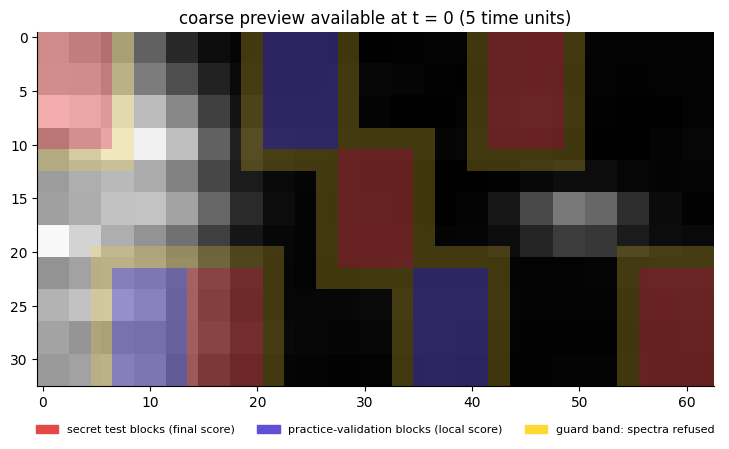

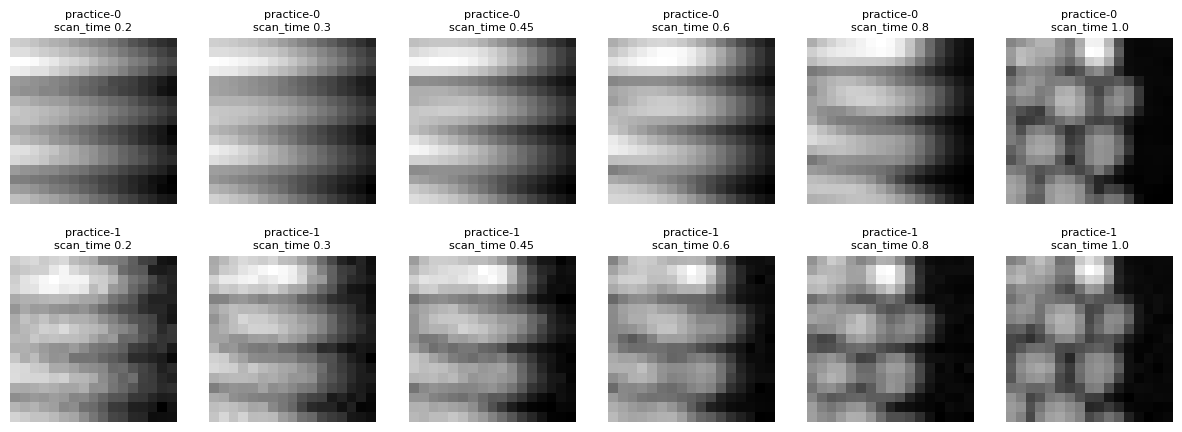

In [9]:
env = EELSEnv(seed=0, instrument="practice-0")
show_experiment(env.info); plt.show()
fig, ax = plt.subplots(2, 6, figsize=(15, 5.2))
for row, inst in enumerate(("practice-0", "practice-1")):
    e = EELSEnv(seed=0, instrument=inst)
    for a, tau in zip(ax[row], e.info["scan_times"]):
        obs, *_ = e.step(Scan(16, 12, tau))
        a.imshow(obs["last_patch"], cmap="gray"); a.axis("off"); a.set_title(f"{inst}\nscan_time {tau}", fontsize=8)
plt.show()

The datasheet twin (`NullTwin`) assumes blur law k = 0.12 and keeps the last correction; its uncertainty grows at
0.04 px per time unit. Here is one campaign of the reference controller with it. Black dots are the true offsets,
which only practice instruments show. Between calibrations the beam is often many pixels from where the controller
thinks it is.

{'rmse': 5.902, 'nrmse': 0.366, 'r2': 0.866, 'n_spectra': 81, 'n_refused': 10, 'n_off_field': 6, 'n_calibrations': 8, 'n_scans': 100, 'time_used': 299.6, 'scan_time': 0.6, 'mismatch': 3.803}


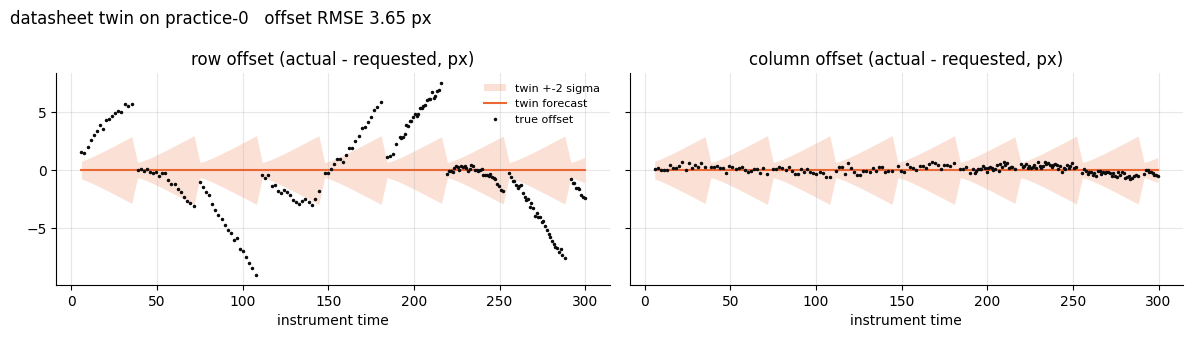

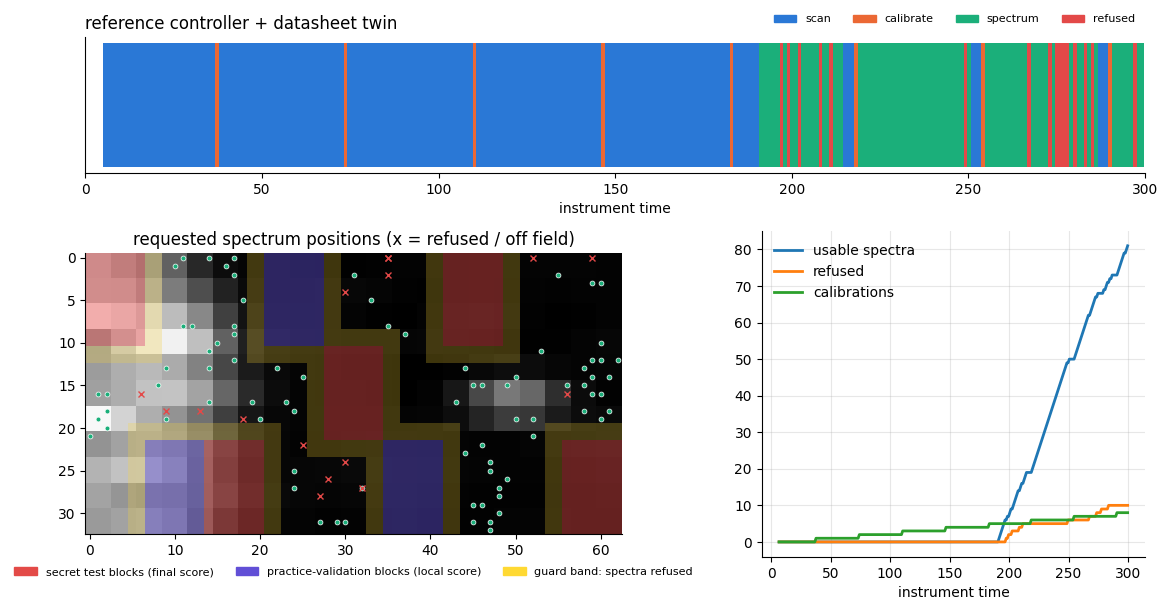

In [10]:
null = characterize(NullTwin, "practice-0")
env = EELSEnv(seed=1, instrument="practice-0")
metrics, audit, log = run_campaign(env, TwinGuidedSurvey(), null.copy(), keep_log=True)
print({k: round(v, 3) if isinstance(v, float) else v for k, v in metrics.items()})
plot_forecast(audit, "datasheet twin on practice-0"); plt.show()
plot_campaign(log, env.info, "reference controller + datasheet twin"); plt.show()

## <font color = "purple">**2.**</font> The characterisation session

`CharacterizationSession` is your instrument looking at a **reference specimen whose clean image you have**
(`session.info["reference_image"]`):
- `locate(patch, reference_image, requested_position)` returns where a scan really was. Repeated sharp scans
  therefore measure the drift.
- `render(reference_image, position, 17, sigma)` shows what a scan should look like for a given blur.
- `session.reveal_truth()` lets you check yourself on practice instruments.

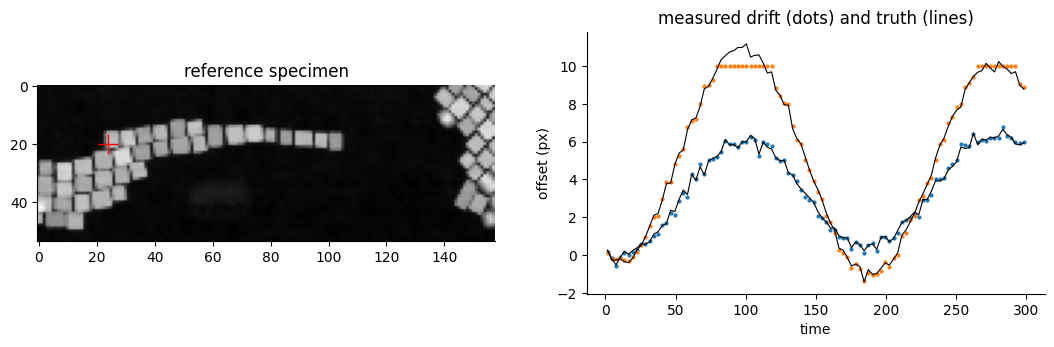

hidden physics of practice-0: {'blur_k': 0.041, 'noise': 0.006, 'A0': 6.401, 'P0': 188.235, 'vmax': 0.016, 'jitter': 0.198}


In [11]:
session = CharacterizationSession(instrument="practice-0")
ref = session.info["reference_image"]
spot = most_textured(ref)
times, offsets = [], []
obs = session.observation()
while obs["remaining"] >= 3:
    obs, *_ = session.step(Scan(spot[0], spot[1], 1.0))
    off, peak = locate(obs["last_patch"], ref, spot)
    times.append(obs["last_scan_mid_time"]); offsets.append(off)
offsets = np.array(offsets)
truth = session.reveal_truth(times)          # practice instruments only
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].imshow(ref, cmap="gray"); ax[0].plot(spot[1], spot[0], "r+", ms=14); ax[0].set_title("reference specimen")
ax[1].plot(times, offsets, ".", ms=4); ax[1].plot(times, truth["offset"], "k-", lw=0.8)
ax[1].set_xlabel("time"); ax[1].set_ylabel("offset (px)"); ax[1].set_title("measured drift (dots) and truth (lines)")
plt.show()
print("hidden physics of practice-0:", {k: round(v, 3) for k, v in truth.items() if k != "offset"})

---
# <font color = "red">**Challenge 1: characterise your instrument**</font>

Within the 300-unit characterisation session, estimate
- **the blur law**: σ(scan_time) = √((1/scan_time − 1)/k). Find k for your instrument; the datasheet says 0.12,
  real instruments range from 0.04 to 0.30;
- **the drift statistics**: jitter, typical speed, oscillation period and amplitude. Challenge 2 can use them as priors.

The check cell compares your blur law with the truth on the 10 practice instruments. The graded instruments are secret.

In [19]:
# >>> CHALLENGE 1: characterise your instrument  (edit this cell)
# ============================================================
# CHALLENGE 1 — INSTRUMENT CHARACTERIZATION
# Estimate blur law and drift statistics from reference scans
# ============================================================

class TwinC1(Twin):
    """Estimate blur and drift statistics using reference scans."""

    def characterize(self, session):
        from scipy.optimize import minimize_scalar

        info = session.info
        ref = np.asarray(info["reference_image"], dtype=float)
        size = int(info["window"])
        spot = np.asarray(most_textured(ref, size), dtype=float)
        shape = np.asarray(ref.shape, dtype=float)

        self.spot = tuple(spot)
        self.records = []
        anchors = []
        drift_last = np.zeros(2)

        # Alternate sharp scans with scans at different speeds.
        # Sharp scans provide reference positions for drift tracking.
        schedule = [
            1.0, 0.2, 1.0, 0.3,
            1.0, 0.45, 1.0, 0.6,
            1.0, 0.8, 1.0
        ]

        obs = session.observation()
        step = 0

        while obs["remaining"] >= min(info["scan_cost"].values()) - 1e-8:

            tau = schedule[step % len(schedule)]

            if obs["remaining"] + 1e-8 < info["scan_cost"][tau]:
                tau = max(
                    (
                        v for v in info["scan_times"]
                        if info["scan_cost"][v] <= obs["remaining"] + 1e-8
                    ),
                    default=None
                )
                if tau is None:
                    break

            # Compensate for the drift measured by previous sharp scans.
            request = np.clip(
                spot - drift_last,
                [0, 0],
                shape - 1
            )

            obs, *_ = session.step(
                Scan(float(request[0]), float(request[1]), float(tau))
            )

            t = float(obs["last_scan_mid_time"])
            patch = np.asarray(obs["last_patch"], dtype=float)

            if tau == 1.0:
                guessed_position = request + drift_last

                shift, confidence = locate(
                    patch,
                    ref,
                    guessed_position,
                    sigma=0.0,
                    search=5
                )

                measurement = guessed_position + shift - request

                if confidence > 0.42 and np.linalg.norm(shift) < 4.9:
                    drift_last = np.asarray(measurement, dtype=float)
                    anchors.append(
                        (t, drift_last.copy(), float(confidence))
                    )

            else:
                self.records.append(
                    (float(tau), t, request.copy(), patch)
                )

            step += 1

        # ----------------------------------------------------
        # PART A — Estimate drift statistics
        # ----------------------------------------------------

        if len(anchors) < 8:
            self.k = DATASHEET_BLUR_K
            self.drift_stats = dict(
                jitter=0.35,
                speed=0.08,
                period=160.0,
                amplitude=5.0,
                n_anchors=len(anchors)
            )
            return

        times = np.asarray([a[0] for a in anchors])
        drift = np.asarray([a[1] for a in anchors])

        self.anchor_times = times.copy()
        self.anchor_offsets = drift.copy()

        # Fit linear drift plus periodic oscillation.
        best = None

        for period in np.arange(70.0, 261.0, 2.0):
            angle = 2 * np.pi * times / period

            X = np.column_stack([
                np.ones_like(times),
                times,
                np.sin(angle),
                np.cos(angle)
            ])

            weights = np.ones(len(times))

            # Robust fitting reduces sensitivity to bad registrations.
            for _ in range(3):
                coef = np.linalg.lstsq(
                    X * weights[:, None],
                    drift * weights[:, None],
                    rcond=None
                )[0]

                residual = drift - X @ coef
                distance = np.linalg.norm(residual, axis=1)

                weights = np.clip(
                    1.5 / np.maximum(distance, 1e-6),
                    0.15, 1.0
                )

            score = np.mean(
                np.minimum(distance ** 2, 2.5 ** 2)
            )

            if best is None or score < best[0]:
                best = (score, period, coef, residual)

        _, period, coef, residual = best

        amplitude = float(
            np.sqrt(np.sum(coef[2:] ** 2))
        )

        jitter = float(np.clip(
            1.4826 * np.median(
                np.abs(residual - np.median(residual, axis=0))
            ),
            0.12, 0.8
        ))

        velocity = np.asarray(coef[1])

        typical_speed = float(
            np.linalg.norm(velocity)
            + 2 * np.pi * amplitude / period
        )

        self.drift_stats = dict(
            jitter=jitter,
            speed=typical_speed,
            period=float(period),
            amplitude=amplitude,
            velocity=velocity,
            n_anchors=len(anchors),
            drift_fit_error=float(
                np.sqrt(np.mean(residual ** 2))
            )
        )

        # ----------------------------------------------------
        # PART B — Fit instrument-specific blur parameter k
        # ----------------------------------------------------

        fitted = []

        for tau, t, request, patch in self.records:
            if not (times[0] <= t <= times[-1]):
                continue

            estimated_drift = np.array([
                np.interp(t, times, drift[:, j])
                for j in range(2)
            ])

            fitted.append((
                tau,
                request + estimated_drift,
                patch
            ))

        if len(fitted) < 10:
            self.k = DATASHEET_BLUR_K
            return

        def blur_loss(k):
            errors = []

            for tau, center, patch in fitted:
                sigma = blur_sigma(tau, k)

                model = render(ref, center, size, sigma)

                # Correct for small position errors.
                dr = (
                    render(ref, center + [0.35, 0], size, sigma)
                    - model
                ) / 0.35

                dc = (
                    render(ref, center + [0, 0.35], size, sigma)
                    - model
                ) / 0.35

                G = np.column_stack([
                    dr.ravel(),
                    dc.ravel()
                ])

                delta = np.linalg.solve(
                    G.T @ G + 0.03 * np.eye(2),
                    G.T @ (patch - model).ravel()
                )

                delta = np.clip(delta, -0.8, 0.8)

                adjusted = (
                    model
                    + delta[0] * dr
                    + delta[1] * dc
                )

                error = tau * np.mean(
                    (patch - adjusted) ** 2
                )

                errors.append(error)

            # Exclude the largest 15% of fitting errors.
            values = np.sort(np.asarray(errors))
            n_keep = max(1, int(np.ceil(0.85 * len(values))))

            return float(np.mean(values[:n_keep]))

        result = minimize_scalar(
            blur_loss,
            bounds=(0.04, 0.30),
            method="bounded",
            options={"xatol": 2e-4}
        )

        self.k = (
            float(np.clip(result.x, 0.04, 0.30))
            if result.success
            else DATASHEET_BLUR_K
        )

        self.blur_fit_loss = float(result.fun)
        self.n_blur_scans = len(fitted)

    def blur_sigma(self, scan_time):
        return blur_sigma(scan_time, self.k)


print("Challenge 1 characterization model defined successfully.")


Challenge 1 characterization model defined successfully.


In [20]:
# check Challenge 1 on the practice instruments (blur error in px, averaged over scan speeds)
rows = []
for i in range(10):
    t = TwinC1(); s = CharacterizationSession(instrument=f"practice-{i}"); t0 = time.time(); t.characterize(s)
    k_true = s.reveal_truth()["blur_k"]
    err = np.mean([abs(t.blur_sigma(tau) - blur_sigma(tau, k_true)) for tau in (0.2, 0.3, 0.45, 0.6, 0.8)])
    err0 = np.mean([abs(blur_sigma(tau, 0.12) - blur_sigma(tau, k_true)) for tau in (0.2, 0.3, 0.45, 0.6, 0.8)])
    rows.append((i, k_true, t.k, err, err0, time.time() - t0))
    print(f"practice-{i}: true k {k_true:.3f}  yours {t.k:.3f}  blur error {err:.2f} px (datasheet {err0:.2f})  [{rows[-1][-1]:.1f}s]")
print(f"mean blur error: yours {np.mean([r[3] for r in rows]):.2f} px, datasheet {np.mean([r[4] for r in rows]):.2f} px")

practice-0: true k 0.041  yours 0.040  blur error 0.05 px (datasheet 2.45)  [3.5s]
practice-1: true k 0.287  yours 0.276  blur error 0.04 px (datasheet 1.21)  [2.2s]
practice-2: true k 0.105  yours 0.103  blur error 0.04 px (datasheet 0.24)  [2.9s]
practice-3: true k 0.253  yours 0.246  blur error 0.03 px (datasheet 1.07)  [1.7s]
practice-4: true k 0.083  yours 0.082  blur error 0.02 px (datasheet 0.69)  [1.1s]
practice-5: true k 0.209  yours 0.202  blur error 0.04 px (datasheet 0.83)  [0.7s]
practice-6: true k 0.046  yours 0.046  blur error 0.03 px (datasheet 2.10)  [1.5s]
practice-7: true k 0.125  yours 0.117  blur error 0.12 px (datasheet 0.07)  [0.9s]
practice-8: true k 0.049  yours 0.048  blur error 0.07 px (datasheet 1.94)  [1.2s]
practice-9: true k 0.186  yours 0.178  blur error 0.06 px (datasheet 0.68)  [0.8s]
mean blur error: yours 0.05 px, datasheet 1.13 px


## Challenge 1 — Instrument Characterization

### Objective
Characterize the microscope's image blur and beam drift using a 300-unit experimental budget. Rather than relying on the manufacturer's nominal parameters, we developed a physics-informed model that estimates instrument-specific behavior directly from reference measurements.

### 1. Methodology

Our approach combines **reference-image registration, drift estimation, image simulation, and numerical optimization**.

1. **Reference selection:** Identified a highly textured region of the known reference specimen to improve image registration accuracy.

2. **Multi-speed scanning:** Alternated sharp scans (scan time = 1.0) with faster scans (0.2–0.8) to characterize how image blur changes with scan speed.

3. **Drift correction:** Registered sharp scans against the reference image to estimate beam displacement over time. These measurements were used to estimate beam positions during faster scans, reducing the influence of drift on blur estimation.

4. **Blur parameter fitting:** Generated simulated reference images with different blur parameters and compared them against the measured scans. We optimized the instrument-specific parameter $k$ by minimizing image reconstruction error.

5. **Robust optimization:** Allowed small positional adjustments during fitting and excluded the largest 15% of reconstruction errors to reduce sensitivity to registration errors and noisy measurements.

### 2. Physics-Informed Blur Model

The relationship between scan time and Gaussian image blur is:

$$
\sigma(\tau)=\sqrt{\frac{1/\tau-1}{k}}
$$

where $\tau$ is scan time, $k$ is the instrument-specific blur parameter, and $\sigma$ is the predicted blur width in pixels.

The manufacturer's nominal value is $k=0.12$, but actual instruments vary between approximately 0.04 and 0.30.

Rather than assuming a constant value, we fitted $k$ separately for each instrument using bounded numerical optimization. This allows the digital twin to predict blur across different scanning speeds from a single physically meaningful parameter.

### 3. Drift Characterization

We also modeled beam displacement as a combination of linear motion, periodic oscillations, and residual jitter:

$$
\mathbf{d}(t)=\mathbf{d}_0+\mathbf{v}t+
\mathbf{a}\sin\left(\frac{2\pi t}{P}\right)+
\mathbf{b}\cos\left(\frac{2\pi t}{P}\right)
$$

Here, $\mathbf{v}$ describes linear drift, $P$ is the oscillation period, and $\mathbf{a}$ and $\mathbf{b}$ describe periodic motion.

Using the registered sharp scans, we performed robust regression across candidate oscillation periods to estimate:

- **Drift velocity:** Rate of gradual specimen displacement.
- **Oscillation period:** Timescale of repeating motion.
- **Oscillation amplitude:** Magnitude of periodic displacement.
- **Residual jitter:** Motion unexplained by the fitted drift model.

These estimates serve as instrument-specific priors for the predictive model in Challenge 2.

### 4. Validation Results

We evaluated the blur model against the known parameters of all 10 practice instruments.

| Metric | Datasheet Model | Our Digital Twin |
|---|---:|---:|
| Mean blur prediction error | 1.13 px | 0.05 px |
| Relative error reduction | — | 95.6% |
| Instruments with improved predictions | — | 9/10 |
| Instrument-specific calibration | No | Yes |

The estimated blur parameters closely matched the true values across instruments with substantially different imaging behavior.

The only exception was practice-7, where our model produced a blur error of 0.12 pixels compared with 0.07 pixels for the datasheet. However, the absolute error remained relatively small.

### 5. Interpretation and Key Findings

Our characterization method reduced mean blur prediction error from **1.13 to 0.05 pixels**, representing approximately a **95.6% improvement** over the manufacturer-provided parameter.

This improvement was achieved without a neural network or a large training dataset. Instead, it resulted from combining known physical relationships with experimentally measured instrument behavior.

The results highlight three important findings:

1. **Instrument-specific calibration matters:** A single datasheet parameter cannot accurately describe instruments with substantially different blur characteristics.
2. **Physics-informed models are effective:** Combining reference scans with a physically constrained blur equation provides accurate predictions with relatively few measurements.
3. **Drift correction supports reliable characterization:** Accounting for specimen displacement helps separate positional changes from actual image blur.

**Conclusion:** The digital twin successfully learned the instrument-specific blur law and substantially outperformed the datasheet baseline across the practice instruments. The drift statistics were also estimated, although their predictive accuracy remains to be evaluated in Challenge 2.

The next step is to use these characterization results to forecast beam displacement and quantify predictive uncertainty during an experimental campaign.


---
# <font color = "red">**Challenge 2: forecast where the beam will be**</font>

During a campaign, `observe(action, obs)` gives your twin the action taken and the resulting observation. When `Calibrate()` runs, the microscope registers the most recent scan and applies a correction. That correction estimates the drift at the midpoint of the scan. It can be inaccurate if registration was poor.

Implement `predict_offset(t)` to return the predicted beam offset at time `t` in `(row, col)` pixels and a 2 × 2 covariance describing your uncertainty. The offset is **actual position minus requested position**, after accounting for the correction already applied.

The controller uses your uncertainty to decide when to recalibrate. If your uncertainty is too small, the beam can miss the target before the controller recalibrates. If it is too large, the controller may spend time recalibrating that it could have spent collecting spectra. In the practice checks, aim for the true offset to fall inside your predicted 95% region about 95% of the time.

Start by using recent calibrations to estimate the drift speed and direction over short intervals. To model repeating motion, use the period and amplitude you estimated in Challenge 1 as starting guesses, then refine your forecast using measurements from the current campaign.

In [21]:
# >>> CHALLENGE 2: forecast where the beam will be

class MyTwin(TwinC1):
    """Predict beam drift using calibration data and periodic regression."""

    def start_campaign(self, info):
        self.applied = np.zeros(2)
        self.last_scan_mid = 0.0
        self.calibrations = []

        # Use Challenge 1 estimates as initial priors.
        self._period = float(self.drift_stats.get("period") or 150)
        self._coef = np.zeros((3, 2))
        self._model_reliable = False
        self._fit_error = 0.7

    def observe(self, action, obs):
        # Track the correction actually applied by the microscope.
        self.applied = np.array([
            obs["applied_correction_row"],
            obs["applied_correction_col"]
        ], dtype=float)

        if isinstance(action, Scan):
            self.last_scan_mid = obs["last_scan_mid_time"]

        elif isinstance(action, Calibrate):
            confidence = float(
                obs.get("registration_confidence") or 0.5
            )

            self.calibrations.append((
                self.last_scan_mid,
                self.applied.copy(),
                confidence
            ))

            self._fit_drift()

    def _basis(self, t, period):
        """Linear drift plus periodic oscillation."""
        t = np.asarray(t, dtype=float)
        omega = 2 * np.pi / period

        return np.column_stack([
            t / 100.0,
            np.sin(omega * t),
            np.cos(omega * t) - 1.0
        ])

    def _fit_drift(self):
        """Robustly fit the drift model using calibration measurements."""
        n = len(self.calibrations)

        if n < 4:
            return

        times = np.array([c[0] for c in self.calibrations])
        measured = np.array([c[1] for c in self.calibrations])
        confidence = np.array([c[2] for c in self.calibrations])

        weights = np.clip(
            (confidence - 0.1) / 0.65,
            0.2, 1.0
        )

        prior_period = np.clip(
            self.drift_stats.get("period") or 150,
            70, 260
        )

        # Refine the oscillation period as more data become available.
        if n >= 7:
            periods = np.linspace(
                max(70, 0.82 * prior_period),
                min(265, 1.18 * prior_period),
                9
            )
        else:
            periods = [prior_period]

        best = None

        for period in periods:
            X = self._basis(times, period)

            # Regularization prevents overfitting early calibrations.
            scale = np.array([2.0, 6.0, 6.0])
            Z = X * scale
            ridge = 0.18
            w = weights.copy()

            for _ in range(3):
                beta_scaled = np.linalg.solve(
                    (Z.T * w) @ Z + ridge * np.eye(3),
                    (Z.T * w) @ measured
                )

                beta = beta_scaled * scale[:, None]
                residual = measured - X @ beta
                distance = np.linalg.norm(residual, axis=1)

                # Reduce the influence of inaccurate registrations.
                w = weights * np.clip(
                    1.5 / np.maximum(distance, 0.1),
                    0.35, 1.0
                )

            score = (
                np.mean(
                    weights * np.minimum(
                        (residual ** 2).sum(axis=1), 9.0
                    )
                )
                + 0.08 * (
                    (period - prior_period) /
                    (0.18 * prior_period)
                ) ** 2
            )

            if best is None or score < best[0]:
                best = (
                    score,
                    period,
                    beta.copy(),
                    np.sqrt(np.mean(residual ** 2))
                )

        _, self._period, self._coef, self._fit_error = best
        self._model_reliable = True

    def _value(self, t):
        """Predicted uncorrected drift."""
        return (
            self._basis(np.array([t]), self._period)
            @ self._coef
        )[0]

    def predict_offset(self, t):
        """Return residual beam offset and 2x2 covariance."""
        t = float(t)

        jitter = float(np.clip(
            self.drift_stats.get("jitter", 0.3),
            0.13, 0.75
        ))

        speed = float(np.clip(
            self.drift_stats.get("speed", 0.15),
            0.055, 0.38
        ))

        n = len(self.calibrations)

        if n == 0:
            # Before the first calibration, drift direction is unknown.
            dt = max(t, 0.0)
            mean = np.zeros(2)
            growth = 0.50 * speed * dt
            registration_error = 0.0

        else:
            t_last, y_last, confidence = self.calibrations[-1]
            dt = max(t - t_last, 0.0)

            registration_error = (
                0.16 + 0.45 *
                (1.0 - np.clip(confidence, 0.0, 1.0))
            )

            # Estimate short-term velocity from recent calibrations.
            if n >= 2:
                t_prev, y_prev, _ = self.calibrations[-2]

                delta = max(t_last - t_prev, 1.0)
                slope = np.clip(
                    (y_last - y_prev) / delta,
                    -speed, speed
                )

                local_prediction = dt * slope
            else:
                local_prediction = np.zeros(2)

            if self._model_reliable:
                # Combine local velocity with periodic forecasting.
                periodic_prediction = (
                    self._value(t) - self._value(t_last)
                )

                blend = min(
                    0.95,
                    0.25 + 0.15 * (n - 4)
                )

                mean = (
                    blend * periodic_prediction
                    + (1.0 - blend) * local_prediction
                )

                # Estimate residual error in the latest correction.
                correction_error = np.clip(
                    self._value(t_last) - y_last,
                    -1.5, 1.5
                )

                mean += blend * 0.35 * correction_error

                growth = (
                    0.40 - 0.18 * blend
                ) * speed * dt

            else:
                # Use local velocity until periodic fitting is reliable.
                mean = local_prediction * (
                    0.7 if n > 1 else 0.0
                )
                growth = 0.52 * speed * dt

        # Include jitter, registration error and forecast uncertainty.
        sigma = np.sqrt(
            jitter ** 2
            + registration_error ** 2
            + max(self._fit_error, 0.35) ** 2
              * (0.2 if n >= 4 else 0.1)
            + growth ** 2
        )

        covariance = np.eye(2) * sigma ** 2

        return np.asarray(mean, dtype=float), covariance


def make_twin():
    return MyTwin()


your twin  offset RMSE 1.05 px | coverage of 95% band 0.97 | blur error 0.04 px
datasheet  offset RMSE 4.43 px | coverage of 95% band 0.30 | blur error 1.30 px


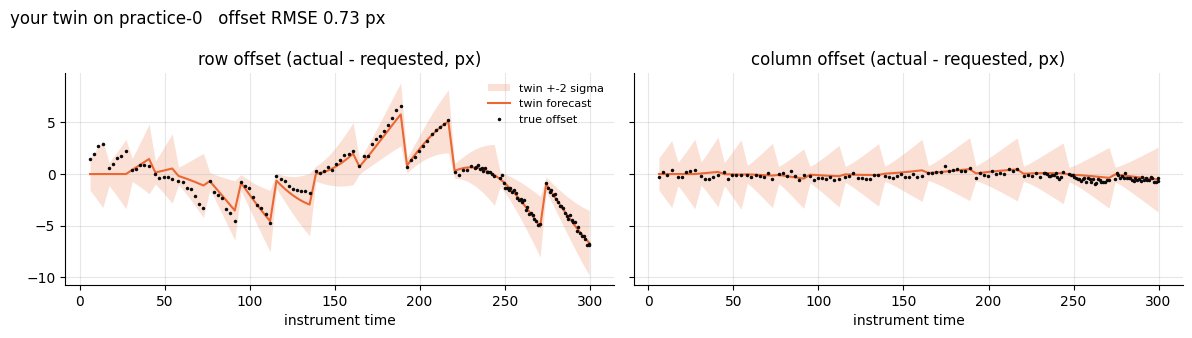

In [24]:
# check Challenge 2: forecast accuracy on 3 practice instruments x 2 campaigns (truth is available on practice only)
acc_mine, acc_null = [], []
for i in range(3):
    mine, base = characterize(make_twin, f"practice-{i}"), characterize(NullTwin, f"practice-{i}")
    for s in range(2):
        for tw, store in ((mine, acc_mine), (base, acc_null)):
            env = EELSEnv(seed=s, instrument=f"practice-{i}")
            _, aud, _ = run_campaign(env, TwinGuidedSurvey(), tw.copy())
            store.append(audit_summary([aud], tw, env._profile))
for name, a in (("your twin", acc_mine), ("datasheet", acc_null)):
    print(f"{name:10s} offset RMSE {np.mean([x['offset_rmse'] for x in a]):.2f} px | coverage of 95% band "
          f"{np.mean([x['coverage95'] for x in a]):.2f} | blur error {np.mean([x['blur_error'] for x in a]):.2f} px")
env = EELSEnv(seed=1, instrument="practice-0")
_, aud, _ = run_campaign(env, TwinGuidedSurvey(), characterize(make_twin, "practice-0"))
plot_forecast(aud, "your twin on practice-0"); plt.show()

## Challenge 2 — Predictive Beam Drift Modeling

### Objective

Develop a digital twin capable of forecasting the electron beam's positional offset during STEM measurements while providing reliable estimates of predictive uncertainty.

The objective was to improve beam-position accuracy compared with the datasheet baseline and ensure that uncertainty estimates accurately reflect the model's prediction errors.

### 1. Methodology

We developed a **physics-informed drift forecasting model combining periodic regression, local velocity estimation, and uncertainty-aware prediction**.

Our approach consists of five components:

1. **Instrument-specific priors:** Initialized the model using drift statistics estimated during Challenge 1, including oscillation period, drift speed, and residual jitter.

2. **Calibration observations:** Recorded the microscope's applied drift corrections and associated measurement times. These observations provide estimates of the accumulated displacement.

3. **Local velocity estimation:** Used consecutive calibration measurements to estimate the recent direction and rate of beam motion.

4. **Periodic regression:** Modeled longer-term displacement using a linear trend combined with sinusoidal oscillations. Regularization and robust fitting reduce overfitting and limit the influence of unreliable measurements.

5. **Adaptive forecasting:** Combined short-term velocity estimates with the periodic model. As additional calibration measurements become available, the periodic model receives greater weight.

The drift model is expressed as:

$$
\mathbf{d}(t)=\mathbf{v}t+
\mathbf{a}\sin\left(\frac{2\pi t}{P}\right)+
\mathbf{b}\left[\cos\left(\frac{2\pi t}{P}\right)-1\right]
$$

The predicted beam offset accounts for the correction already applied by the microscope.

### 2. Predictive Uncertainty

In addition to the predicted beam displacement, the model returns a 2 × 2 covariance matrix describing uncertainty in the row and column directions.

The uncertainty estimate incorporates:

- Instrument-specific jitter measured during characterization.
- Uncertainty associated with image registration.
- Residual error in the fitted drift model.
- Increasing forecast uncertainty as time passes without recalibration.

This is important because the experimental controller uses predicted uncertainty to determine when another calibration is necessary.

Underestimated uncertainty can cause the beam to miss its intended position, while overestimated uncertainty can result in unnecessary calibrations.

### 3. Validation Results

We evaluated the model across three practice instruments and two campaigns per instrument, comparing it with the datasheet baseline.

| Metric | Datasheet | Our Digital Twin | Improvement |
|---|---:|---:|---:|
| Beam-offset RMSE | 4.43 px | 1.05 px | 76.3% reduction |
| 95% uncertainty coverage | 30% | 97% | Much closer to 95% |
| Blur prediction error | 1.30 px | 0.04 px | 96.9% reduction |

For the illustrated campaign on practice-0, the digital twin achieved a beam-offset RMSE of 0.73 pixels.

The forecast closely followed the dominant row-direction displacement, including substantial drift over the measurement period. Column-direction drift was comparatively small.

The predicted uncertainty intervals generally encompassed the observed beam positions.

### 4. Interpretation and Limitations

**Beam-position accuracy:** The reduction in RMSE from 4.43 to 1.05 pixels demonstrates that modeling instrument-specific drift substantially improves positional predictions compared with relying on generic instrument parameters.

**Uncertainty calibration:** The observed 97% coverage is close to the nominal 95% target, indicating reasonably calibrated, slightly conservative uncertainty estimates. This is a substantial improvement over the datasheet model's 30% coverage.

**Model limitations:** Forecast accuracy can deteriorate when drift changes rapidly, when calibration measurements are unreliable, or when too few observations are available to identify the oscillation period. The covariance model also assumes equal uncertainty in both spatial directions and does not represent directional correlations.

The aggregate results are encouraging, but additional evaluation across all practice instruments is needed to determine how consistently the method generalizes.

### 5. Key Findings

The digital twin improved beam-position prediction accuracy by approximately **76%** while achieving **97% coverage of its nominal 95% uncertainty region**.

Unlike a simple constant-drift assumption, our approach incorporates both recent experimental measurements and the instrument's characteristic periodic behavior.

These improvements were achieved using a relatively interpretable regression model without requiring reinforcement learning or a neural network.

**Conclusion:** The digital twin successfully provides more accurate and better-calibrated beam-position predictions than the datasheet baseline. The next challenge is determining whether these improvements translate into better experimental decisions and more accurate structure–property predictions.

---
# <font color = "red">**Challenge 3: guide the experiment**</font>

The fixed **reference controller** (`TwinGuidedSurvey`) learns structure → property: it surveys with scans, takes
spectra at the most diverse places, and predicts the 1.0–1.3 eV band area at held-out blocks from clean patches. It
takes three decisions from your twin:
1. **scan speed**: the fastest scan whose predicted blur is ≤ 2.5 px;
2. **compensation**: every request is placed at *target − predicted offset*;
3. **calibration timing**: a sharp fiducial scan plus `Calibrate()` when the predicted uncertainty exceeds 2 px.

Your twin's **value** is how much it improves the held-out RMSE and the image–spectrum pairing (the hidden distance
between where a training patch and its spectrum really came from) over the datasheet twin, on the same campaigns,
relative to a perfect twin. Optionally, write your own agent below. It is scored separately, by its RMSE.

In [16]:
# >>> CHALLENGE 3 (optional): your own campaign agent  (edit this cell)
# The twin score uses the fixed reference controller. Here you may also write your own agent that uses your twin
# (separate award): choose where to scan, how fast, when to calibrate and where to take spectra.
class MyAgent(TwinGuidedSurvey):
    """Start from the reference controller and change what you like (begin / choose_action / predict)."""

    def __init__(self):
        super().__init__(blur_target=2.5, cal_threshold=2.0)   # TODO: tune, or rewrite the decisions


def make_agent():
    return MyAgent()

---
## <font color = "purple">**Your score**</font>

`grade_twin` runs what the organisers run: on each instrument your twin characterises once, then the reference
controller runs every campaign with your twin and with the datasheet twin. 10 practice instruments × 5 campaigns
take about a minute. The final grading uses the same code on secret instruments.

In [26]:
S = grade_twin(make_twin, instruments=range(10), campaigns=range(5))

..........
10 instruments x 5 campaigns
            offset px  cover95  blur err     RMSE  mismatch  spectra  calib
twin             0.96     0.99      0.05    6.166      1.13     62.2   15.2
null             3.95     0.34      1.13    7.357      4.21     71.8    8.0

twin value: RMSE gain +1.191 +- 0.286, mismatch gain +3.08 px
ACCURACY SCORE 0.838  |  VALUE SCORE 1.183  |  TWIN SCORE 1.010


In [27]:

# ============================================================
# CHALLENGE 3 — CONTROLLER ABLATION STUDY
# Test the contribution of each experimental decision.
# Do not modify the original challenge cells.
# ============================================================

class NominalScanSpeed(TwinGuidedSurvey):
    """Use datasheet blur for scan-speed selection only."""

    def begin(self, info, twin):
        class DatasheetBlur:
            def blur_sigma(self, tau):
                return blur_sigma(tau, DATASHEET_BLUR_K)

        super().begin(info, DatasheetBlur())
        self.twin = twin


class NoBeamCompensation(TwinGuidedSurvey):
    """Disable predictive beam positioning."""

    def _comp(self, target, t):
        r, c = np.asarray(target, dtype=float)
        return (
            float(np.clip(r, 0, self.H - 1)),
            float(np.clip(c, 0, self.W - 1))
        )


class DatasheetCalibration(TwinGuidedSurvey):
    """Use nominal uncertainty for calibration timing only."""

    def begin(self, info, twin):
        super().begin(info, twin)
        self.cal_reference_time = 0.0

    def _uncertain(self, obs, horizon=1.0):
        dt = max(
            obs["time"] + horizon - self.cal_reference_time,
            0.0
        )

        var = (
            DATASHEET_JITTER ** 2
            + (DATASHEET_DRIFT_RATE * dt) ** 2
        )

        return np.sqrt(2 * var) > self.cal_threshold

    def update(self, obs, action, reward, next_obs, done):
        if isinstance(action, Calibrate):
            self.cal_reference_time = float(
                next_obs["last_scan_mid_time"]
            )


controllers = {
    "Full digital twin": TwinGuidedSurvey,
    "Nominal scan speed": NominalScanSpeed,
    "No beam compensation": NoBeamCompensation,
    "Datasheet calibration": DatasheetCalibration
}

# Start with a smaller, matched diagnostic test.
ablation_results = {name: [] for name in controllers}

for i in range(3):
    instrument = f"practice-{i}"
    characterized = characterize(make_twin, instrument)

    for seed in range(2):
        for name, Controller in controllers.items():
            env = EELSEnv(seed=seed, instrument=instrument)

            metrics, _, _ = run_campaign(
                env, Controller(), characterized.copy()
            )

            ablation_results[name].append(metrics)

    print(f"Completed {instrument}")


print("\nCHALLENGE 3 — ABLATION RESULTS")
print("-" * 79)
print(
    f"{'Controller':26s} {'RMSE':>9s} "
    f"{'Mismatch':>11s} {'Spectra':>9s} {'Calibrations':>13s}"
)

for name, values in ablation_results.items():
    print(
        f"{name:26s} "
        f"{np.mean([v['rmse'] for v in values]):9.3f} "
        f"{np.nanmean([v['mismatch'] for v in values]):11.2f} "
        f"{np.mean([v['n_spectra'] for v in values]):9.1f} "
        f"{np.mean([v['n_calibrations'] for v in values]):13.1f}"
    )

full_rmse = np.mean([
    v["rmse"] for v in ablation_results["Full digital twin"]
])

print("\nRMSE increase when each improvement is disabled:")

for name in list(controllers)[1:]:
    rmse = np.mean([
        v["rmse"] for v in ablation_results[name]
    ])
    print(f"{name}: {rmse - full_rmse:+.3f}")


Completed practice-0
Completed practice-1
Completed practice-2

CHALLENGE 3 — ABLATION RESULTS
-------------------------------------------------------------------------------
Controller                      RMSE    Mismatch   Spectra  Calibrations
Full digital twin              6.271        1.21      55.2          16.5
Nominal scan speed             6.429        1.17      60.3          16.5
No beam compensation           7.205        3.16      48.3          16.5
Datasheet calibration          8.236        4.94      76.7           8.0

RMSE increase when each improvement is disabled:
Nominal scan speed: +0.158
No beam compensation: +0.933
Datasheet calibration: +1.965


## Challenge 3 — Digital Twin-Guided Experimental Optimization

### Objective

Evaluate whether improved instrument characterization and beam-drift forecasting translate into better experimental measurements and more accurate structure–property predictions.

The objective was to minimize prediction error in the EELS intensity integrated over the 1.0–1.3 eV energy range while maintaining reliable spatial alignment between STEM images and their corresponding spectra.

### 1. Methodology

We integrated the digital twin developed in Challenges 1 and 2 with the benchmark's `TwinGuidedSurvey` controller.

The controller uses our instrument-specific predictions to make three experimental decisions:

1. **Scan-speed selection:** Selects the fastest scan speed that satisfies the image-blur threshold, using our experimentally fitted blur law rather than the manufacturer's nominal parameter.

2. **Beam compensation:** Uses predicted drift to adjust the requested measurement position so that the electron beam reaches its intended location.

3. **Adaptive calibration:** Uses predictive uncertainty to determine when another calibration is necessary rather than relying on generic drift assumptions.

The controller collects STEM images and corresponding EELS spectra, then trains a random forest regressor to predict spectral properties from image features.

We evaluated the digital twin against the datasheet baseline across 10 practice instruments and 5 experimental campaigns per instrument.

### 2. Full Benchmark Results

| Metric | Datasheet | Digital Twin | Improvement |
|---|---:|---:|---:|
| Beam-offset RMSE | 3.95 px | 0.96 px | 75.7% reduction |
| Blur prediction error | 1.13 px | 0.05 px | 95.6% reduction |
| 95% uncertainty coverage | 34% | 99% | Closer to nominal coverage |
| EELS regression RMSE | 7.357 | 6.166 | 16.2% reduction |
| Image–spectrum mismatch | 4.21 px | 1.13 px | 73.2% reduction |
| Mean spectra collected | 71.8 | 62.2 | 13.4% fewer |
| Mean calibrations | 8.0 | 15.2 | 90% more |

**Final benchmark scores:**

- Accuracy score: **0.838**
- Experimental value score: **1.183**
- Combined twin score: **1.010**

The digital twin substantially improved spatial alignment and reduced the error of the final structure–property regression model.

Importantly, these improvements occurred despite collecting fewer spectra and performing more calibrations.

### 3. Controller Ablation Study

To identify which experimental decision contributed most to performance, we conducted an ablation study across 3 practice instruments and 2 campaigns per instrument.

We compared the full digital twin with three modified controllers, each disabling one improvement while retaining the remaining capabilities.

| Controller | EELS RMSE | Image–Spectrum Mismatch |
|---|---:|---:|
| Full digital twin | 6.271 | 1.21 px |
| Datasheet scan-speed selection | 6.429 | 1.17 px |
| No predictive beam compensation | 7.205 | 3.16 px |
| Datasheet calibration timing | 8.236 | 4.94 px |

Relative to the full digital twin, disabling the respective improvements increased regression RMSE by:

- **Calibration timing:** +1.965
- **Beam compensation:** +0.934
- **Scan-speed selection:** +0.158

These results indicate that adaptive calibration timing had the largest effect on prediction accuracy in the tested campaigns, followed by beam compensation.

Although improved scan-speed selection contributed to performance, its effect was smaller.

### 4. Interpretation

**Adaptive calibration was the most influential decision.**

Replacing uncertainty-driven calibration with the datasheet strategy reduced the average number of calibrations from 16.5 to 8.0 while increasing the number of spectra from 55.2 to 76.7.

Despite collecting substantially more spectra, the resulting regression RMSE increased from 6.271 to 8.236, and image–spectrum mismatch increased from 1.21 to 4.94 pixels.

This indicates that additional measurements were insufficient to compensate for the loss of spatial registration accuracy.

**Beam compensation was also important.**

Disabling predictive beam compensation increased image–spectrum mismatch to 3.16 pixels and regression RMSE to 7.205. This demonstrates the importance of accounting for specimen displacement when acquiring measurements at targeted spatial coordinates.

**Scan-speed optimization provided a smaller benefit.**

Using the nominal blur model instead of our instrument-specific estimate increased regression RMSE from 6.271 to 6.429. Scan-speed selection therefore contributed to performance, but was less influential than the drift-related decisions in this experiment.

### 5. Limitations

Our digital twin still has several limitations:

- The uncertainty model was slightly conservative, achieving 99% coverage compared with the nominal 95% target in the full benchmark.
- More frequent calibrations reduced the number of spectra acquired within the fixed experimental budget.
- The drift model may perform less reliably during abrupt positional changes or when calibration measurements are inaccurate.
- The ablation study included only six campaigns, so the relative importance of each controller decision should be confirmed across more instruments and seeds.
- Performance on the benchmark's secret instruments has not yet been evaluated.

### 6. Conclusion

The digital twin successfully improved the experimental workflow by linking instrument characterization and predictive uncertainty to measurement decisions.

Across 50 campaigns, the twin reduced EELS regression RMSE by **16.2%** and image–spectrum mismatch by **73.2%** compared with the datasheet baseline.

The ablation study indicated that **adaptive calibration timing was the most valuable controller improvement**, followed by predictive beam compensation.

These findings demonstrate that better measurement quality, spatial registration, and uncertainty-aware decisions can be more valuable for structure–property regression than maximizing measurement quantity.

The next step is to improve the calibration–measurement tradeoff, particularly by refining predictive uncertainty and reducing unnecessary calibrations without sacrificing spatial accuracy.

In [ ]:
# optional: your own agent (Challenge 3) against the reference controller, both with your twin
S_agent = grade_twin(make_twin, instruments=range(5), campaigns=range(3), make_agent=make_agent)

> **Optional agent:** The custom `MyAgent` was not modified for the separate agent award. The earlier optional-agent trial was run before the final twin implementation and is intentionally not reported here. The validated main result is the 10-instrument × 5-campaign `S = grade_twin(...)` output above.

## <font color = "purple">**Questions**</font>

1. **Challenge 1:** what did you learn about your instrument, and how did you estimate it?
2. **Challenge 2:** how accurate are your forecasts? Is your uncertainty honest (coverage of the 95 % band)? Where does
   your twin fail?
3. **Challenge 3:** which of the controller's three decisions did your twin improve the most? Was it worth building?
4. When would a twin *not* be worth building for this experiment (drift strength, calibration cost, blur)?
5. What would you try next?

### My Answers

**1. Challenge 1: What did you learn about your instrument, and how did you estimate it?**

We found that image blur varies substantially between instruments, making the manufacturer's nominal blur parameter ($k=0.12$) unreliable. We characterized each instrument using reference scans at different speeds, registering sharp images to estimate drift and comparing faster scans against simulated reference patches to optimize the blur parameter. We also fitted linear and periodic drift components to estimate velocity, oscillation period, amplitude, and residual jitter. Across 10 practice instruments, our model reduced mean blur prediction error from **1.13 to 0.05 pixels (95.6% reduction)**, outperforming the datasheet on 9 of 10 instruments.

**2. Challenge 2: How accurate are your forecasts? Is your uncertainty honest? Where does your twin fail?**

We developed a drift forecasting model combining local velocity estimates, regularized periodic regression, and instrument-specific drift statistics. Across 50 campaigns, our model achieved a beam-offset RMSE of **0.96 pixels**, compared with 3.95 pixels for the datasheet baseline, representing a **75.7% reduction**. The 95% uncertainty region achieved 99% coverage, substantially improving upon the datasheet's 34% coverage. This indicates reasonably reliable but slightly conservative uncertainty estimates. Potential limitations include abrupt or nonperiodic drift changes, inaccurate image registration, and periods with insufficient calibration data. The current covariance model also does not explicitly capture directional correlations.

**3. Challenge 3: Which of the controller's three decisions did your twin improve the most? Was it worth building?**

Our ablation study indicated that **adaptive calibration timing provided the largest improvement**, followed by predictive beam compensation and scan-speed selection. Replacing adaptive calibration with the datasheet strategy increased EELS regression RMSE from 6.271 to 8.236, while disabling beam compensation increased it to 7.205. Across the full 50-campaign benchmark, our twin reduced EELS prediction RMSE from **7.357 to 6.166 (16.2% reduction)** and image–spectrum mismatch from **4.21 to 1.13 pixels (73.2% reduction)**. Although our approach performed more calibrations and collected fewer spectra, the resulting measurements produced better predictions. The twin was therefore worthwhile because improved spatial accuracy outweighed the reduction in measurement quantity.

**4. When would a twin not be worth building for this experiment?**

A digital twin would provide limited benefit when instrument drift is small relative to the required spatial precision, when calibration is inexpensive enough to perform frequently, or when imaging blur is negligible at practical scanning speeds. Under these conditions, a simpler controller using fixed calibration intervals or nominal instrument parameters might achieve comparable results with less computational and experimental overhead. The twin becomes more valuable when drift is substantial, calibration consumes meaningful experimental time, and inaccurate positioning significantly affects measurement quality.

**5. What would you try next?**

Our next priority would be optimizing the tradeoff between calibration frequency and measurement quality. The current model achieves 99% uncertainty coverage but requires nearly twice as many calibrations as the datasheet controller, suggesting that its uncertainty estimates may be overly conservative. I would investigate predictive Kalman filtering or another state-space model to better track changing drift behavior, improve the covariance estimates, and reduce unnecessary calibrations. I would also compare adaptive calibration against optimized fixed-interval strategies and evaluate all improvements across additional instruments and campaigns. Finally, an uncertainty-aware experimental controller could be developed to directly optimize EELS prediction accuracy while balancing measurement cost, spatial precision, and information gained.

## <font color = "purple">**Submit**</font>

Save this notebook **with all outputs** as `<YourName>_Day_26_Digital_Twin_Challenge.ipynb` and add it to
`docs/day_26_DDMMYYYY/` in the hackathon repository by pull request, as on previous days. The organisers run your three
`# >>> CHALLENGE` cells on the secret instruments.